In [1]:
# Generic inputs for most ML tasks
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
# This is new
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.ensemble import RandomForestRegressor

pd.options.display.float_format = '{:,.2f}'.format

# setup interactive notebook mode
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

from IPython.display import display, HTML

### Fetching Flight data

In [2]:
# fetch data 

mco_syr_sw_data = pd.read_csv('flight_data/mco_syr_sw_combined.csv')
mco_syr_jb_data = pd.read_csv('flight_data/mco_syr_jb_combined.csv')
jfk_syr_jb_data = pd.read_csv('flight_data/jfk_syr_jb_combined.csv')
jfk_syr_end_data = pd.read_csv('flight_data/jfk_syr_dl_combined.csv')
ord_syr_ua_data = pd.read_csv('flight_data/ord_syr_ua_combined.csv')
ord_syr_aa_data = pd.read_csv('flight_data/ord_syr_aa_combined.csv')

In [3]:
dfs = [ord_syr_aa_data,ord_syr_ua_data,jfk_syr_end_data,jfk_syr_jb_data,mco_syr_jb_data,mco_syr_sw_data]
main_data = pd.concat(dfs,axis = 0)
main_data.head()
len(main_data)

,Unnamed: 0,Carrier_Code,Date,Flight_Number,Tail_Number,Destination_Airport,Scheduled departure time,Actual departure time,Scheduled elapsed time (Minutes),Actual elapsed time (Minutes),...,Wheels-on Time,Taxi-In time (Minutes),arr_Delay_Carrier,arr_Delay_Weather,arr_Delay_National_Aviation_System,arr_Delay_Security,arr_Delay_Late_Aircraft_Arrival,arr_hour,arr_day,arr_year
0,0,MQ,2020-01-04,"3,580.00",N240NN,SYR,7:55,8:21,112.00,87.00,...,10:43,5.00,0.00,0.00,0.00,0.00,0.00,10,5,2020
1,1,MQ,2020-01-11,"3,946.00",N247NN,SYR,15:00,15:09,108.00,132.00,...,18:13,8.00,9.00,0.00,24.00,0.00,0.00,17,5,2020
2,2,MQ,2020-01-18,"3,946.00",N265NN,SYR,15:00,16:27,108.00,147.00,...,19:45,9.00,0.00,4.00,39.00,0.00,83.00,17,5,2020
3,3,MQ,2020-01-25,"3,946.00",N281NN,SYR,15:00,14:55,108.00,126.00,...,17:56,5.00,0.00,0.00,0.00,0.00,0.00,17,5,2020
4,4,MQ,2020-02-01,"3,946.00",N283NN,SYR,15:00,14:57,108.00,99.00,...,17:32,4.00,0.00,0.00,0.00,0.00,0.00,17,5,2020


8661

In [4]:
main_data.isna().sum()

Unnamed: 0                             0
Carrier_Code                           0
Date                                   0
Flight_Number                          0
Tail_Number                           74
Destination_Airport                    0
Scheduled departure time               0
Actual departure time                  0
Scheduled elapsed time (Minutes)       0
Actual elapsed time (Minutes)          0
Departure delay (Minutes)              0
Wheels-off time                        0
Taxi-Out time (Minutes)                0
dep_Delay_Carrier                      0
dep_Delay_Weather                      0
dep_Delay_National_Aviation_System     0
dep_Delay_Security                     0
dep_Delay_Late_Aircraft_Arrival        0
dep_hour                               0
dep_day                                0
dep_year                               0
dep_order                              0
Origin_Airport                         0
Scheduled Arrival Time                 0
Actual Arrival T

In [5]:
main_data.dtypes

Unnamed: 0                              int64
Carrier_Code                           object
Date                                   object
Flight_Number                         float64
Tail_Number                            object
Destination_Airport                    object
Scheduled departure time               object
Actual departure time                  object
Scheduled elapsed time (Minutes)      float64
Actual elapsed time (Minutes)         float64
Departure delay (Minutes)             float64
Wheels-off time                        object
Taxi-Out time (Minutes)               float64
dep_Delay_Carrier                     float64
dep_Delay_Weather                     float64
dep_Delay_National_Aviation_System    float64
dep_Delay_Security                    float64
dep_Delay_Late_Aircraft_Arrival       float64
dep_hour                                int64
dep_day                                 int64
dep_year                                int64
dep_order                         

### Preprocessing flight data

In [6]:
sub_data = main_data.drop(columns = ['Unnamed: 0','Destination_Airport','Actual departure time','Scheduled elapsed time (Minutes)','Actual elapsed time (Minutes)',
                         'Wheels-off time','Taxi-Out time (Minutes)','dep_Delay_Carrier',
                         'dep_Delay_Weather','dep_Delay_National_Aviation_System','dep_Delay_Security','dep_Delay_Late_Aircraft_Arrival',
                         'dep_year','Actual Arrival Time','Wheels-on Time','Taxi-In time (Minutes)','arr_Delay_Carrier','arr_Delay_Weather',
                         'arr_Delay_National_Aviation_System','arr_Delay_Security','arr_Delay_Late_Aircraft_Arrival','arr_year'])

In [7]:
sub_data.dtypes


Carrier_Code                  object
Date                          object
Flight_Number                float64
Tail_Number                   object
Scheduled departure time      object
Departure delay (Minutes)    float64
dep_hour                       int64
dep_day                        int64
dep_order                     object
Origin_Airport                object
Scheduled Arrival Time        object
Arrival Delay (Minutes)      float64
arr_hour                       int64
arr_day                        int64
dtype: object

In [8]:
sub_data.head()

,Carrier_Code,Date,Flight_Number,Tail_Number,Scheduled departure time,Departure delay (Minutes),dep_hour,dep_day,dep_order,Origin_Airport,Scheduled Arrival Time,Arrival Delay (Minutes),arr_hour,arr_day
0,MQ,2020-01-04,"3,580.00",N240NN,7:55,26.00,7,5,latter,ORD,10:47,1.00,10,5
1,MQ,2020-01-11,"3,946.00",N247NN,15:00,9.00,15,5,latter,ORD,17:48,33.00,17,5
2,MQ,2020-01-18,"3,946.00",N265NN,15:00,87.00,15,5,latter,ORD,17:48,126.00,17,5
3,MQ,2020-01-25,"3,946.00",N281NN,15:00,-5.00,15,5,latter,ORD,17:48,13.00,17,5
4,MQ,2020-02-01,"3,946.00",N283NN,15:00,-3.00,15,5,latter,ORD,17:48,-12.00,17,5


In [9]:
sub_data['dep_min'] = sub_data['Scheduled departure time'].str.split(":").str[1].astype('int64')
sub_data['Date'] = pd.to_datetime( sub_data['Date'],format ="%Y-%m-%d")
sub_data['Date'] = sub_data['Date'].dt.strftime('%m/%d/%Y')
sub_data['dep_hours'] = sub_data['dep_hour'].astype('object')
sub_data['dep_min'] = sub_data['dep_min'].astype('object')
sub_data['arr_min'] = main_data['Scheduled Arrival Time'].str.split(":").str[1].astype('int64')
sub_data['arr_hours'] = sub_data['arr_hour'].astype('object')
sub_data['arr_min'] = sub_data['arr_min'].astype('object')
sub_data['Flight_Number'] = main_data['Flight_Number'].astype('object')
sub_data['dep_hour'] = main_data['dep_hour'].astype('object')
sub_data['dep_day'] = main_data['dep_day'].astype('object')
sub_data['arr_hour'] = main_data['arr_hour'].astype('object')
sub_data['arr_day'] = main_data['arr_day'].astype('object')
conditions = [
    (sub_data['Arrival Delay (Minutes)'] > 5),
    (sub_data['Arrival Delay (Minutes)'] >=-5) & (sub_data['Arrival Delay (Minutes)'] <= 5),
    (sub_data['Arrival Delay (Minutes)'] < -5)
]
conditions2 = [
    (sub_data['Departure delay (Minutes)'] > 5),
    (sub_data['Departure delay (Minutes)'] >=-5) & (sub_data['Departure delay (Minutes)'] <= 5),
    (sub_data['Departure delay (Minutes)'] < -5)
]
choices = [2,1,0]
sub_data['arr_status'] = np.select(conditions, choices)
sub_data['dep_status'] = np.select(conditions2, choices)
sub_data.dtypes
sub_data.head()
len(sub_data)

Carrier_Code                  object
Date                          object
Flight_Number                 object
Tail_Number                   object
Scheduled departure time      object
Departure delay (Minutes)    float64
dep_hour                      object
dep_day                       object
dep_order                     object
Origin_Airport                object
Scheduled Arrival Time        object
Arrival Delay (Minutes)      float64
arr_hour                      object
arr_day                       object
dep_min                       object
dep_hours                     object
arr_min                       object
arr_hours                     object
arr_status                     int32
dep_status                     int32
dtype: object

,Carrier_Code,Date,Flight_Number,Tail_Number,Scheduled departure time,Departure delay (Minutes),dep_hour,dep_day,dep_order,Origin_Airport,Scheduled Arrival Time,Arrival Delay (Minutes),arr_hour,arr_day,dep_min,dep_hours,arr_min,arr_hours,arr_status,dep_status
0,MQ,01/04/2020,"3,580.00",N240NN,7:55,26.00,7,5,latter,ORD,10:47,1.00,10,5,55,7,47,10,1,2
1,MQ,01/11/2020,"3,946.00",N247NN,15:00,9.00,15,5,latter,ORD,17:48,33.00,17,5,0,15,48,17,2,2
2,MQ,01/18/2020,"3,946.00",N265NN,15:00,87.00,15,5,latter,ORD,17:48,126.00,17,5,0,15,48,17,2,2
3,MQ,01/25/2020,"3,946.00",N281NN,15:00,-5.00,15,5,latter,ORD,17:48,13.00,17,5,0,15,48,17,2,1
4,MQ,02/01/2020,"3,946.00",N283NN,15:00,-3.00,15,5,latter,ORD,17:48,-12.00,17,5,0,15,48,17,0,1


8661

In [10]:
#sub_data.to_csv('sub_data.csv', index=False)

### Filtering flights with arrival delay less than 120 mins

In [11]:
len(sub_data)
sub_data= sub_data[sub_data['Arrival Delay (Minutes)'] < 120]
len(sub_data)

8661

8405

### Fetching Weather data

In [12]:
# Read and process weather data files for each airport

jfk_weather_data = pd.read_csv('weather_data/JFK_weather_data_hourly_processed.csv')
syr_weather_data = pd.read_csv('weather_data/SYR_weather_data_hourly_processed.csv')
ord_weather_data = pd.read_csv('weather_data/ORD_weather_data_hourly_processed.csv')
mco_weather_data = pd.read_csv('weather_data/MCO_weather_data_hourly_processed.csv')

# Combine weather data for all airports
weather_dfs = [jfk_weather_data, ord_weather_data, mco_weather_data]
weather_data = pd.concat(weather_dfs, axis=0)
weather_data['dep_hours'] = weather_data['dep_hours'].astype('object')
syr_weather_data['arr_hours'] = syr_weather_data['arr_hours'].astype('object')
weather_data.head()
syr_weather_data.head()
weather_data.dtypes
syr_weather_data.dtypes




,dep_azimuth,dep_clouds,dep_dewpt,dep_elev_angle,dep_h_angle,dep_precip,dep_pres,dep_revision_status,dep_rh,dep_snow,dep_temp,dep_vis,dep_weather.description,dep_weather.code,dep_wind_dir,dep_wind_gust_spd,dep_wind_spd,Date,dep_hours,Origin_Airport
0,261.20,100,3.80,-26.20,NaN,0.00,1002,final,88,0.00,5.60,16,Overcast clouds,804,220,6.00,3.60,12/31/2019,19,JFK
1,270.50,100,3.90,-37.50,NaN,0.25,1003,final,85,0.00,6.30,16,Overcast clouds,804,220,6.80,5.37,12/31/2019,20,JFK
2,281.40,100,3.70,-48.80,NaN,0.00,1003,final,82,0.00,6.50,16,Overcast clouds,804,255,8.00,7.45,12/31/2019,21,JFK
3,296.30,100,1.60,-59.60,NaN,0.00,1002,final,73,0.00,6.10,16,Overcast clouds,804,270,9.30,6.70,12/31/2019,22,JFK
4,320.80,100,0.70,-68.60,NaN,0.00,1003,final,69,0.00,6.00,16,Overcast clouds,804,270,10.40,7.45,12/31/2019,23,JFK


,arr_azimuth,arr_clouds,arr_dewpt,arr_elev_angle,arr_h_angle,arr_precip,arr_pres,arr_revision_status,arr_rh,arr_snow,arr_temp,arr_vis,arr_weather.description,arr_weather.code,arr_wind_dir,arr_wind_gust_spd,arr_wind_spd,Date,arr_hours
0,260.90,100,-2.30,-24.90,NaN,0.00,987,final,78,0.00,1.10,14,Overcast clouds,804,240,9.60,4.59,12/31/2019,19
1,270.70,100,-3.00,-35.80,NaN,0.00,987,final,77,0.00,0.60,16,Overcast clouds,804,240,9.60,4.59,12/31/2019,20
2,282.10,100,-4.00,-46.60,NaN,0.00,986,final,71,0.00,0.60,16,Overcast clouds,804,240,10.40,5.70,12/31/2019,21
3,297.00,100,-4.40,-56.90,NaN,0.00,987,final,69,0.00,0.60,16,Overcast clouds,804,250,10.40,6.20,12/31/2019,22
4,319.80,100,-4.40,-65.60,NaN,0.00,986,final,69,0.00,0.60,14,Overcast clouds,804,250,10.80,6.20,12/31/2019,23


dep_azimuth                float64
dep_clouds                   int64
dep_dewpt                  float64
dep_elev_angle             float64
dep_h_angle                float64
dep_precip                 float64
dep_pres                     int64
dep_revision_status         object
dep_rh                       int64
dep_snow                   float64
dep_temp                   float64
dep_vis                      int64
dep_weather.description     object
dep_weather.code             int64
dep_wind_dir                 int64
dep_wind_gust_spd          float64
dep_wind_spd               float64
Date                        object
dep_hours                   object
Origin_Airport              object
dtype: object

arr_azimuth                float64
arr_clouds                   int64
arr_dewpt                  float64
arr_elev_angle             float64
arr_h_angle                float64
arr_precip                 float64
arr_pres                     int64
arr_revision_status         object
arr_rh                       int64
arr_snow                   float64
arr_temp                   float64
arr_vis                      int64
arr_weather.description     object
arr_weather.code             int64
arr_wind_dir                 int64
arr_wind_gust_spd          float64
arr_wind_spd               float64
Date                        object
arr_hours                   object
dtype: object

### Merging flight and weather data

In [13]:
sub_data = pd.merge(sub_data, weather_data, how='left', on=['Origin_Airport', 'Date', 'dep_hours'])

sub_data.head()

,Carrier_Code,Date,Flight_Number,Tail_Number,Scheduled departure time,Departure delay (Minutes),dep_hour,dep_day,dep_order,Origin_Airport,...,dep_revision_status,dep_rh,dep_snow,dep_temp,dep_vis,dep_weather.description,dep_weather.code,dep_wind_dir,dep_wind_gust_spd,dep_wind_spd
0,MQ,01/04/2020,"3,580.00",N240NN,7:55,26.00,7,5,latter,ORD,...,final,88,0.00,-1.10,11,Overcast clouds,804,320,6.80,3.10
1,MQ,01/11/2020,"3,946.00",N247NN,15:00,9.00,15,5,latter,ORD,...,final,96,8.50,-0.60,2,Light snow,600,20,15.90,10.80
2,MQ,01/25/2020,"3,946.00",N281NN,15:00,-5.00,15,5,latter,ORD,...,final,92,4.00,0.80,6,Light snow,600,255,8.20,4.34
3,MQ,02/01/2020,"3,946.00",N283NN,15:00,-3.00,15,5,latter,ORD,...,final,73,0.00,2.40,16,Overcast clouds,804,255,10.40,5.37
4,MQ,02/08/2020,"3,946.00",N274NN,15:00,-4.00,15,5,latter,ORD,...,final,56,0.00,1.60,16,Overcast clouds,804,235,7.60,3.85


In [14]:
# Define merging logic based on airport code
sub_data = pd.merge(sub_data, syr_weather_data, how='left', on=['Date', 'arr_hours'])
sub_data.head()



,Carrier_Code,Date,Flight_Number,Tail_Number,Scheduled departure time,Departure delay (Minutes),dep_hour,dep_day,dep_order,Origin_Airport,...,arr_revision_status,arr_rh,arr_snow,arr_temp,arr_vis,arr_weather.description,arr_weather.code,arr_wind_dir,arr_wind_gust_spd,arr_wind_spd
0,MQ,01/04/2020,"3,580.00",N240NN,7:55,26.00,7,5,latter,ORD,...,final,92,0.00,2.80,6,Light rain,500,350,5.09,5.09
1,MQ,01/11/2020,"3,946.00",N247NN,15:00,9.00,15,5,latter,ORD,...,final,83,0.00,15.00,16,Light rain,500,150,11.50,2.10
2,MQ,01/25/2020,"3,946.00",N281NN,15:00,-5.00,15,5,latter,ORD,...,final,96,1.50,1.10,3,Sleet,611,110,2.60,2.60
3,MQ,02/01/2020,"3,946.00",N283NN,15:00,-3.00,15,5,latter,ORD,...,final,75,0.00,0.00,16,Overcast clouds,804,245,1.60,0.80
4,MQ,02/08/2020,"3,946.00",N274NN,15:00,-4.00,15,5,latter,ORD,...,final,64,0.00,-8.90,16,Overcast clouds,804,245,2.80,1.20


In [15]:
sub_data.isna().sum()

Carrier_Code                    0
Date                            0
Flight_Number                   0
Tail_Number                    74
Scheduled departure time        0
Departure delay (Minutes)       0
dep_hour                        0
dep_day                         0
dep_order                       0
Origin_Airport                  0
Scheduled Arrival Time          0
Arrival Delay (Minutes)         0
arr_hour                        0
arr_day                         0
dep_min                         0
dep_hours                       0
arr_min                         0
arr_hours                       0
arr_status                      0
dep_status                      0
dep_azimuth                     0
dep_clouds                      0
dep_dewpt                       0
dep_elev_angle                  0
dep_h_angle                  8405
dep_precip                      0
dep_pres                        0
dep_revision_status             0
dep_rh                          0
dep_snow      

In [16]:
sub_data.columns

Index(['Carrier_Code', 'Date', 'Flight_Number', 'Tail_Number',
       'Scheduled departure time', 'Departure delay (Minutes)', 'dep_hour',
       'dep_day', 'dep_order', 'Origin_Airport', 'Scheduled Arrival Time',
       'Arrival Delay (Minutes)', 'arr_hour', 'arr_day', 'dep_min',
       'dep_hours', 'arr_min', 'arr_hours', 'arr_status', 'dep_status',
       'dep_azimuth', 'dep_clouds', 'dep_dewpt', 'dep_elev_angle',
       'dep_h_angle', 'dep_precip', 'dep_pres', 'dep_revision_status',
       'dep_rh', 'dep_snow', 'dep_temp', 'dep_vis', 'dep_weather.description',
       'dep_weather.code', 'dep_wind_dir', 'dep_wind_gust_spd', 'dep_wind_spd',
       'arr_azimuth', 'arr_clouds', 'arr_dewpt', 'arr_elev_angle',
       'arr_h_angle', 'arr_precip', 'arr_pres', 'arr_revision_status',
       'arr_rh', 'arr_snow', 'arr_temp', 'arr_vis', 'arr_weather.description',
       'arr_weather.code', 'arr_wind_dir', 'arr_wind_gust_spd',
       'arr_wind_spd'],
      dtype='object')

In [17]:
sub_data.drop(columns= ['Carrier_Code','Date','Flight_Number','Tail_Number','arr_azimuth',
                       'Scheduled departure time','Scheduled Arrival Time','dep_order', 
                        'arr_hours', 'dep_hours','arr_weather.description', 'dep_weather.description',
                        'Arrival Delay (Minutes)','Departure delay (Minutes)','arr_elev_angle','arr_h_angle',
                        'arr_revision_status','dep_elev_angle','dep_h_angle','dep_revision_status','dep_azimuth'],
              inplace = True)


In [18]:
sub_data.dtypes
sub_data.columns
sub_data.head()
sub_data.isna().sum()

dep_hour              object
dep_day               object
Origin_Airport        object
arr_hour              object
arr_day               object
dep_min               object
arr_min               object
arr_status             int32
dep_status             int32
dep_clouds             int64
dep_dewpt            float64
dep_precip           float64
dep_pres               int64
dep_rh                 int64
dep_snow             float64
dep_temp             float64
dep_vis                int64
dep_weather.code       int64
dep_wind_dir           int64
dep_wind_gust_spd    float64
dep_wind_spd         float64
arr_clouds             int64
arr_dewpt            float64
arr_precip           float64
arr_pres               int64
arr_rh                 int64
arr_snow             float64
arr_temp             float64
arr_vis                int64
arr_weather.code       int64
arr_wind_dir           int64
arr_wind_gust_spd    float64
arr_wind_spd         float64
dtype: object

Index(['dep_hour', 'dep_day', 'Origin_Airport', 'arr_hour', 'arr_day',
       'dep_min', 'arr_min', 'arr_status', 'dep_status', 'dep_clouds',
       'dep_dewpt', 'dep_precip', 'dep_pres', 'dep_rh', 'dep_snow', 'dep_temp',
       'dep_vis', 'dep_weather.code', 'dep_wind_dir', 'dep_wind_gust_spd',
       'dep_wind_spd', 'arr_clouds', 'arr_dewpt', 'arr_precip', 'arr_pres',
       'arr_rh', 'arr_snow', 'arr_temp', 'arr_vis', 'arr_weather.code',
       'arr_wind_dir', 'arr_wind_gust_spd', 'arr_wind_spd'],
      dtype='object')

,dep_hour,dep_day,Origin_Airport,arr_hour,arr_day,dep_min,arr_min,arr_status,dep_status,dep_clouds,...,arr_precip,arr_pres,arr_rh,arr_snow,arr_temp,arr_vis,arr_weather.code,arr_wind_dir,arr_wind_gust_spd,arr_wind_spd
0,7,5,ORD,10,5,55,47,1,2,100,...,1.50,991,92,0.00,2.80,6,500,350,5.09,5.09
1,15,5,ORD,17,5,0,48,2,2,100,...,1.50,994,83,0.00,15.00,16,500,150,11.50,2.10
2,15,5,ORD,17,5,0,48,2,1,100,...,1.50,994,96,1.50,1.10,3,611,110,2.60,2.60
3,15,5,ORD,17,5,0,48,0,1,100,...,0.00,994,75,0.00,0.00,16,804,245,1.60,0.80
4,15,5,ORD,17,5,0,48,0,1,100,...,0.00,1009,64,0.00,-8.90,16,804,245,2.80,1.20


dep_hour             0
dep_day              0
Origin_Airport       0
arr_hour             0
arr_day              0
dep_min              0
arr_min              0
arr_status           0
dep_status           0
dep_clouds           0
dep_dewpt            0
dep_precip           0
dep_pres             0
dep_rh               0
dep_snow             0
dep_temp             0
dep_vis              0
dep_weather.code     0
dep_wind_dir         0
dep_wind_gust_spd    0
dep_wind_spd         0
arr_clouds           0
arr_dewpt            0
arr_precip           0
arr_pres             0
arr_rh               0
arr_snow             0
arr_temp             0
arr_vis              0
arr_weather.code     0
arr_wind_dir         0
arr_wind_gust_spd    0
arr_wind_spd         0
dtype: int64

In [19]:
#sub_data.to_csv('merged_data.csv', index=False)


### Analysing combined data

In [20]:
# define function to import viz libraries
import plotly
plotly.offline.init_notebook_mode(connected=True)
from plotly.graph_objs import *
from plotly import tools
import plotly.graph_objects as go
import seaborn as sns

Index(['dep_hour', 'dep_day', 'Origin_Airport', 'arr_hour', 'arr_day',
       'dep_min', 'arr_min', 'arr_status', 'dep_status', 'dep_clouds',
       'dep_dewpt', 'dep_precip', 'dep_pres', 'dep_rh', 'dep_snow', 'dep_temp',
       'dep_vis', 'dep_weather.code', 'dep_wind_dir', 'dep_wind_gust_spd',
       'dep_wind_spd', 'arr_clouds', 'arr_dewpt', 'arr_precip', 'arr_pres',
       'arr_rh', 'arr_snow', 'arr_temp', 'arr_vis', 'arr_weather.code',
       'arr_wind_dir', 'arr_wind_gust_spd', 'arr_wind_spd'],
      dtype='object')


<Axes: >

dep_hour


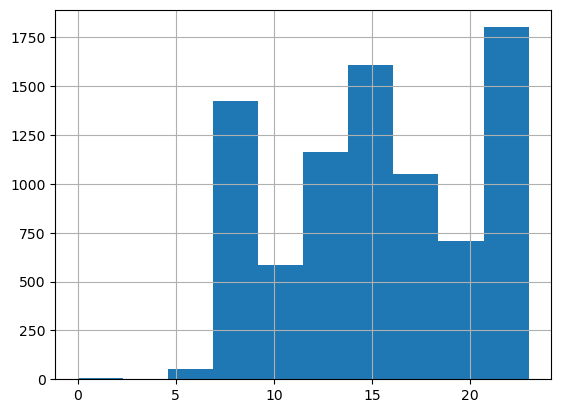

<Axes: >

dep_day


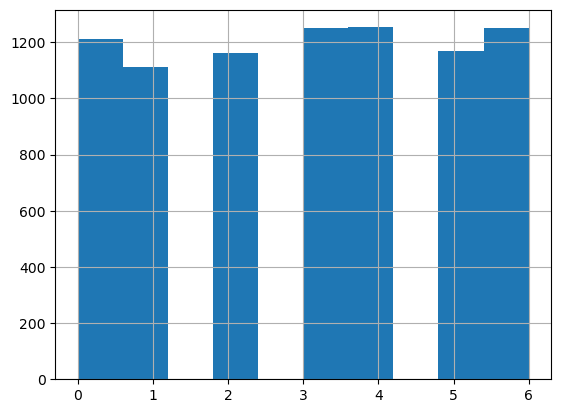

<Axes: >

Origin_Airport


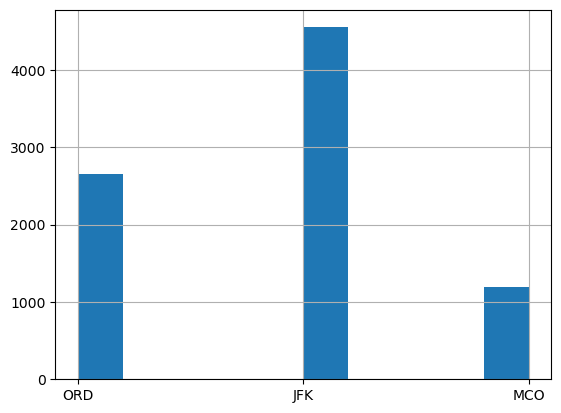

<Axes: >

arr_hour


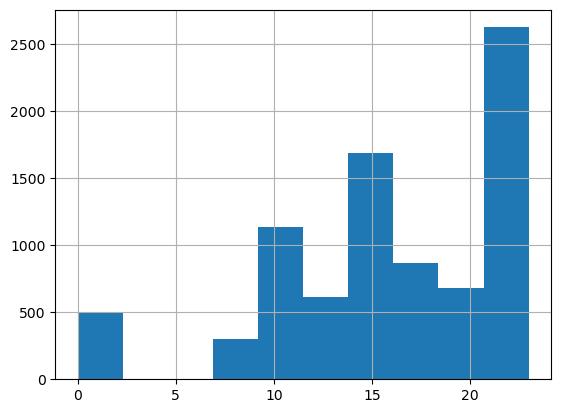

<Axes: >

arr_day


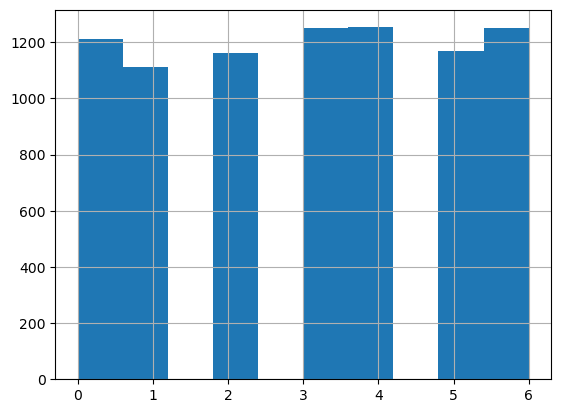

<Axes: >

dep_min


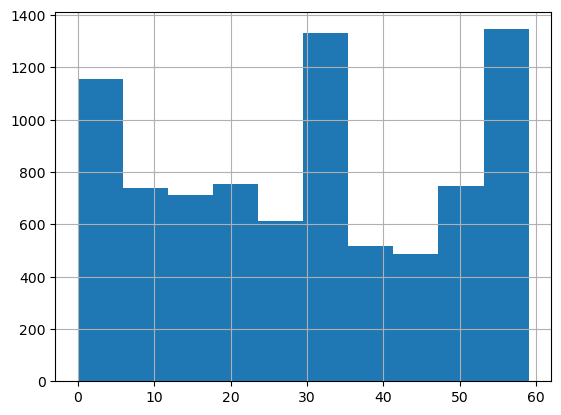

<Axes: >

arr_min


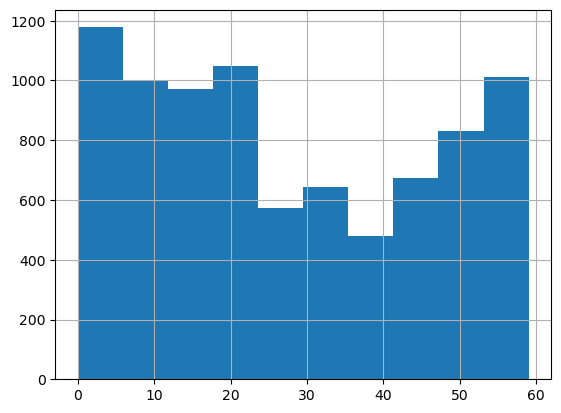

<Axes: >

arr_status


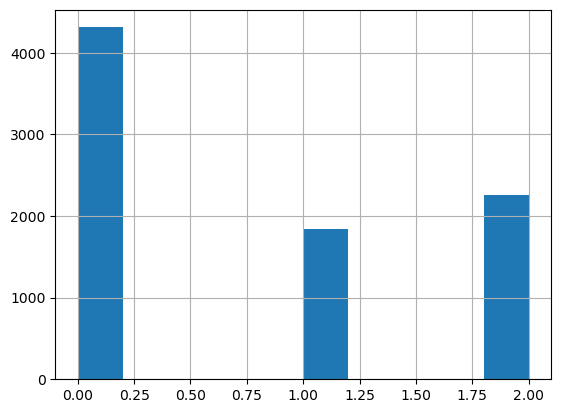

<Axes: >

dep_status


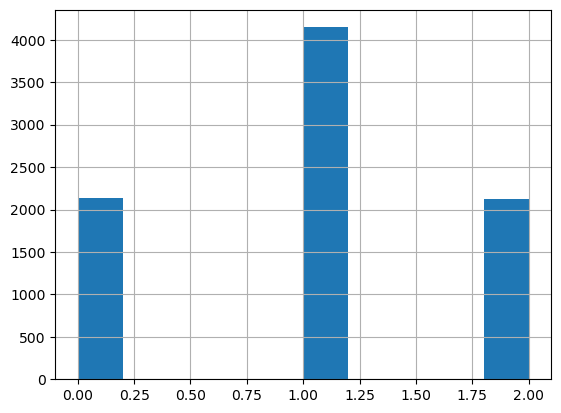

<Axes: >

dep_clouds


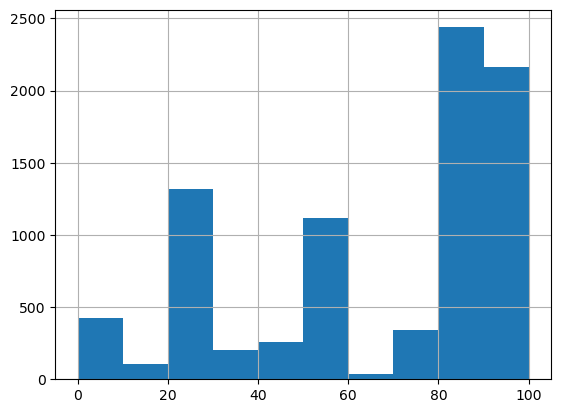

<Axes: >

dep_dewpt


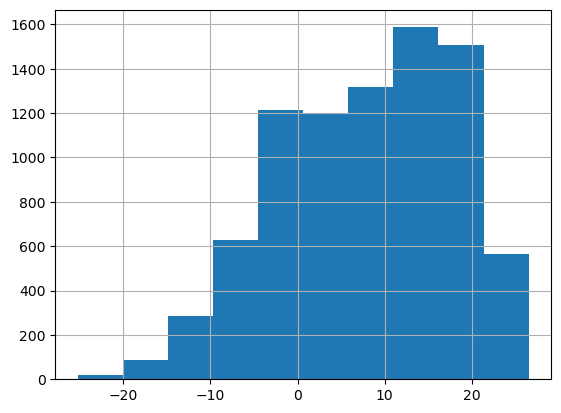

<Axes: >

dep_precip


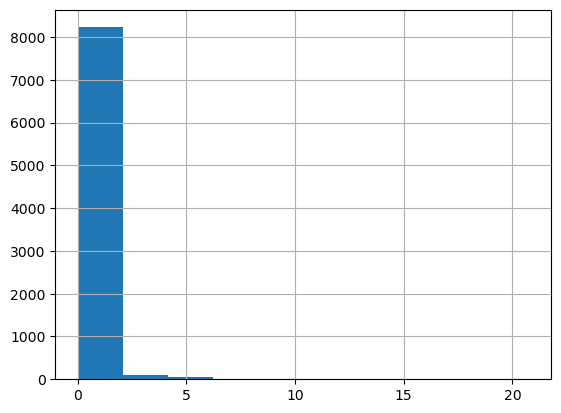

<Axes: >

dep_pres


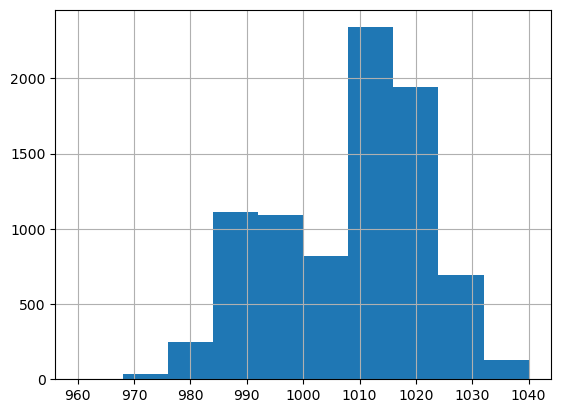

<Axes: >

dep_rh


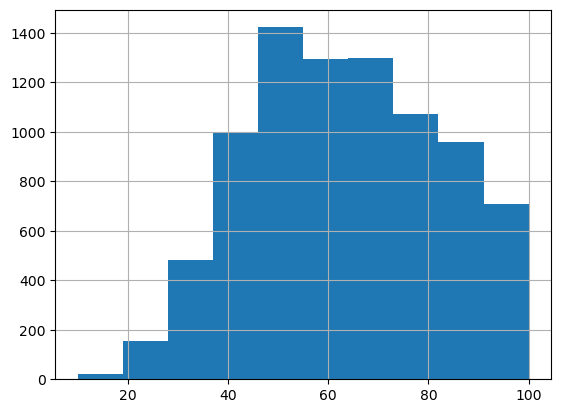

<Axes: >

dep_snow


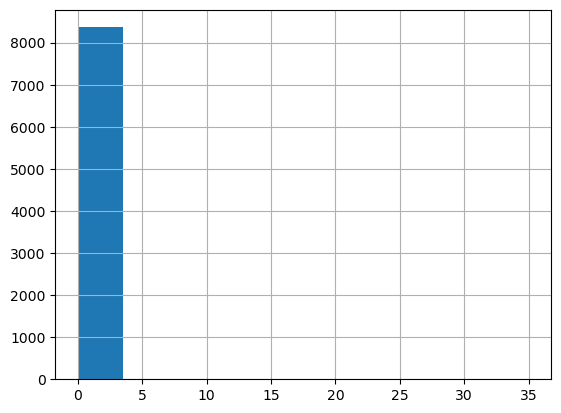

<Axes: >

dep_temp


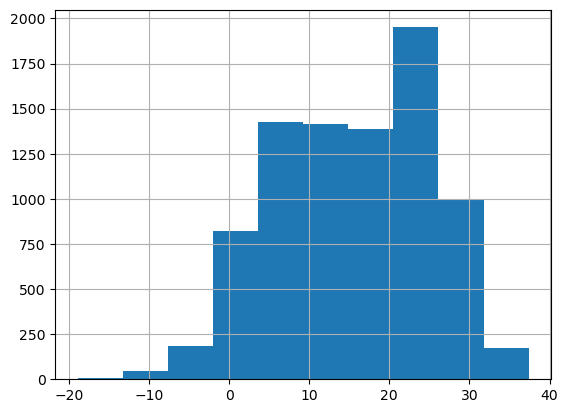

<Axes: >

dep_vis


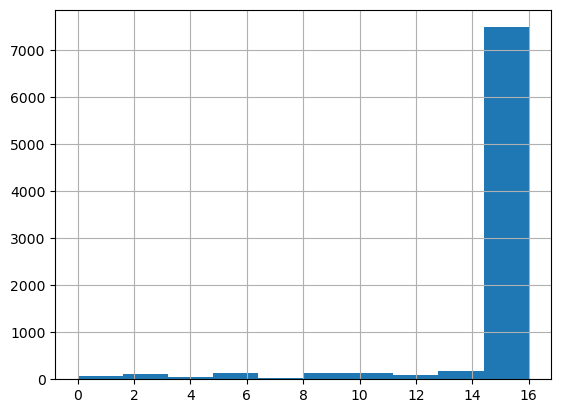

<Axes: >

dep_weather.code


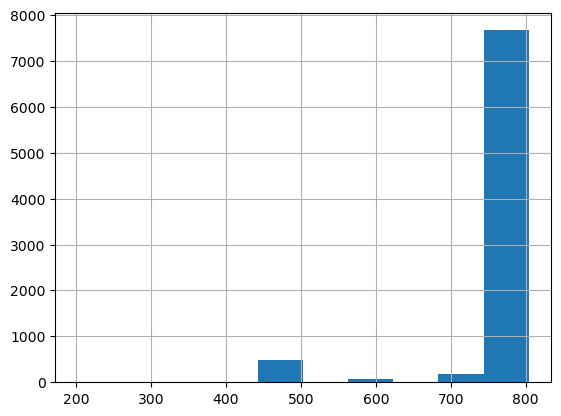

<Axes: >

dep_wind_dir


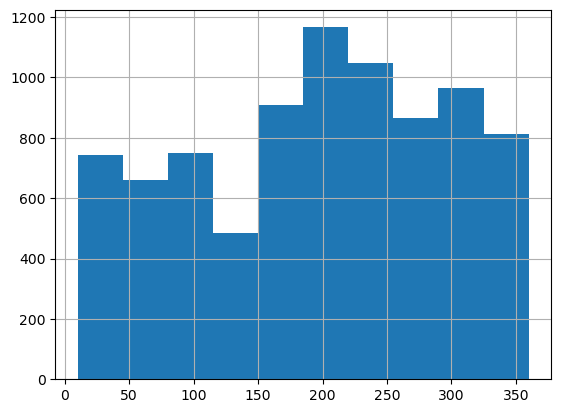

<Axes: >

dep_wind_gust_spd


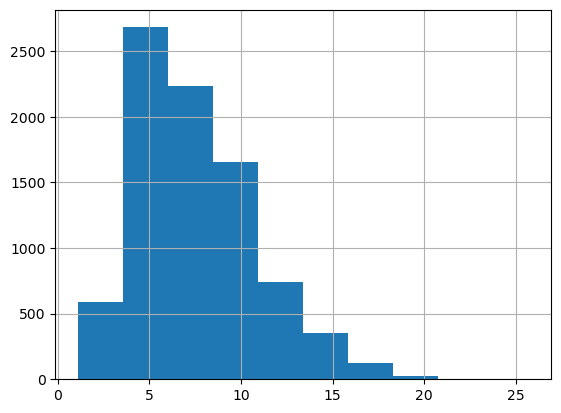

<Axes: >

dep_wind_spd


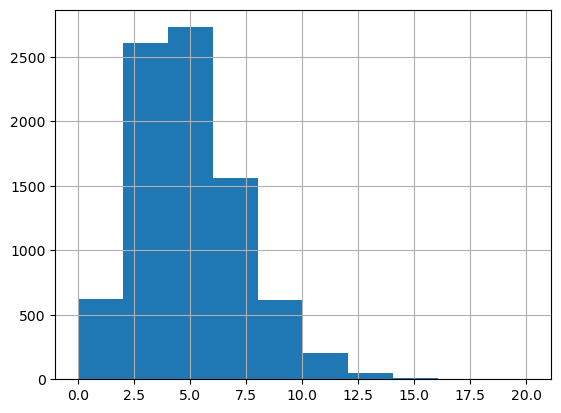

<Axes: >

arr_clouds


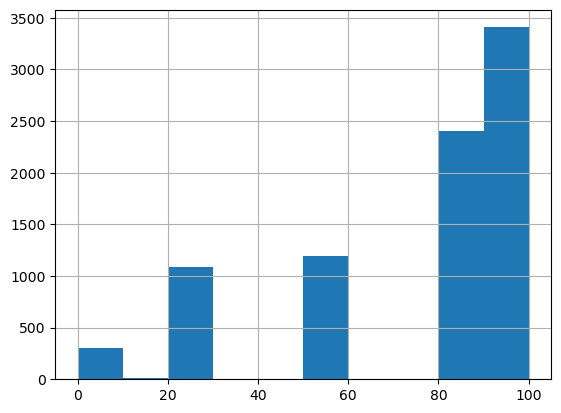

<Axes: >

arr_dewpt


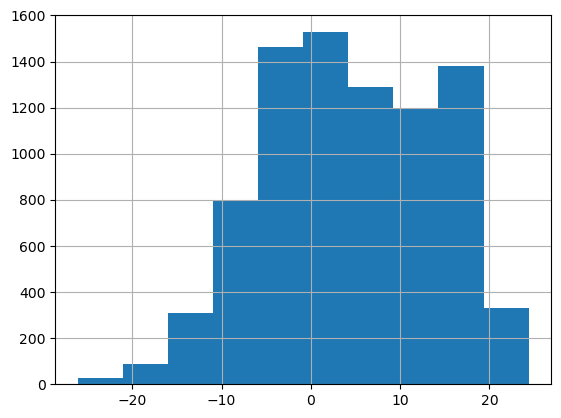

<Axes: >

arr_precip


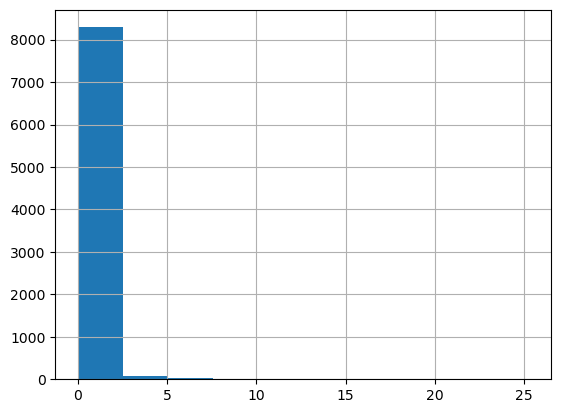

<Axes: >

arr_pres


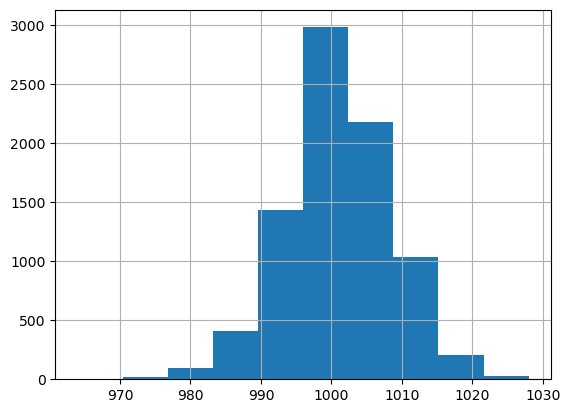

<Axes: >

arr_rh


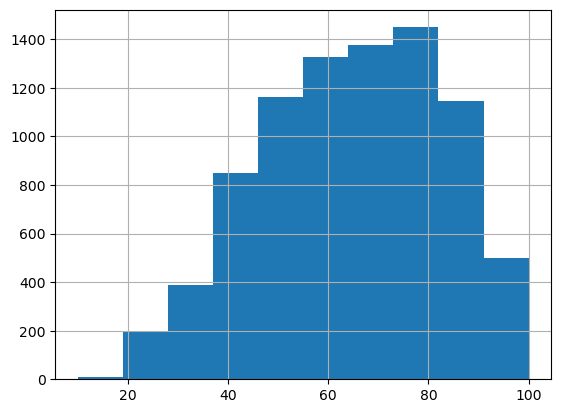

<Axes: >

arr_snow


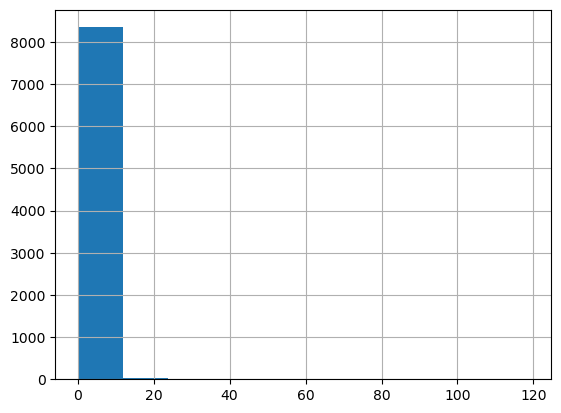

<Axes: >

arr_temp


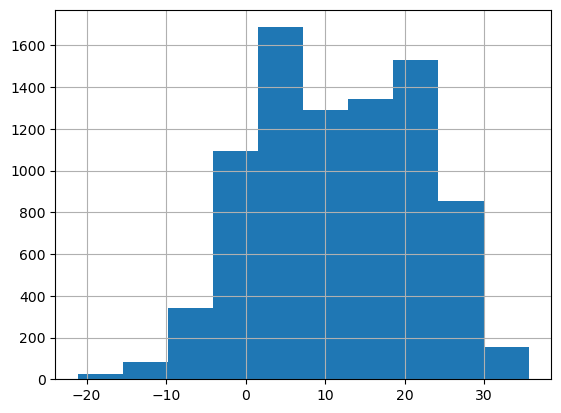

<Axes: >

arr_vis


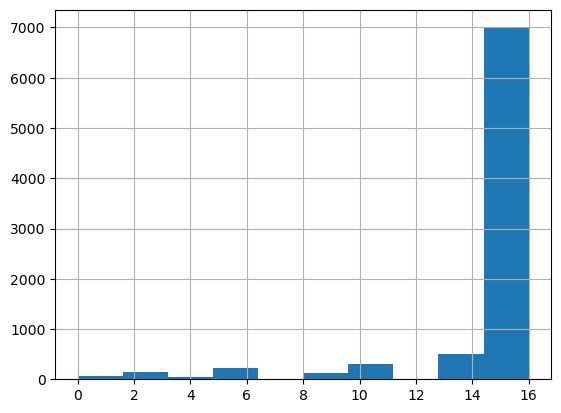

<Axes: >

arr_weather.code


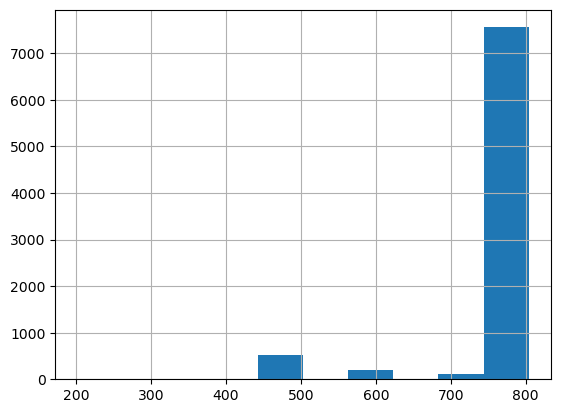

<Axes: >

arr_wind_dir


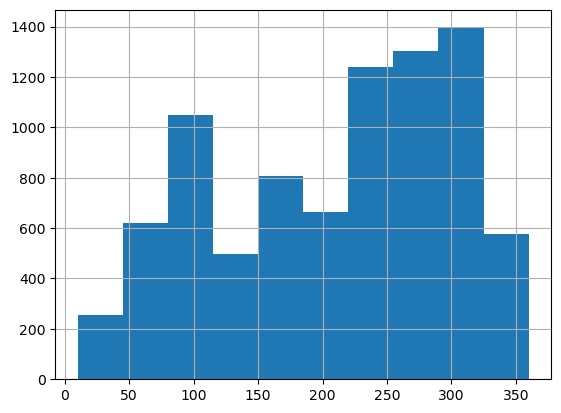

<Axes: >

arr_wind_gust_spd


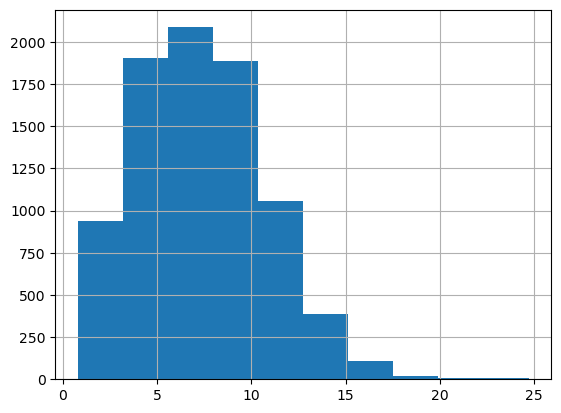

<Axes: >

arr_wind_spd


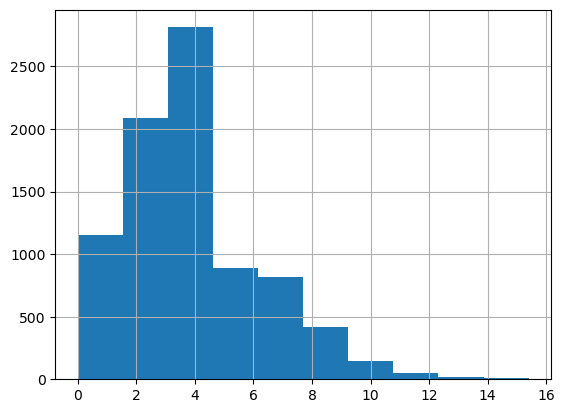

In [21]:
cols = sub_data.columns
print(cols)
for col in cols: 
    sub_data[col].hist()
    print(col)
    plt.show()

In [22]:
import plotly.express as px

In [23]:
sub_data.columns

Index(['dep_hour', 'dep_day', 'Origin_Airport', 'arr_hour', 'arr_day',
       'dep_min', 'arr_min', 'arr_status', 'dep_status', 'dep_clouds',
       'dep_dewpt', 'dep_precip', 'dep_pres', 'dep_rh', 'dep_snow', 'dep_temp',
       'dep_vis', 'dep_weather.code', 'dep_wind_dir', 'dep_wind_gust_spd',
       'dep_wind_spd', 'arr_clouds', 'arr_dewpt', 'arr_precip', 'arr_pres',
       'arr_rh', 'arr_snow', 'arr_temp', 'arr_vis', 'arr_weather.code',
       'arr_wind_dir', 'arr_wind_gust_spd', 'arr_wind_spd'],
      dtype='object')

In [24]:
#for co in sub_data.columns:
fig = px.scatter(sub_data, y='arr_precip', x='arr_status', title='delay Over columns')
fig.show()

### Squaring precip columns

In [25]:
sub_data['dep_precip'] = sub_data['dep_precip']**2
sub_data['arr_precip'] = sub_data['arr_precip']**2

In [26]:
# correl = subset_data.corr()
correl = sub_data.corr(numeric_only=True)

trace = go.Heatmap(z=correl.values,
                  x=correl.index.values,
                  y=correl.columns.values)
data=[trace]
plotly.offline.iplot(data, filename='basic-heatmap')

In [27]:
su_data = sub_data
su_data['dep_hour'] = pd.Categorical(su_data['dep_hour'], categories=[i for i in range(24)])
su_data['dep_day'] = pd.Categorical(su_data['dep_day'], categories=[i for i in range(7)])
su_data['dep_min'] = pd.Categorical(su_data['dep_min'], categories=[i for i in range(60)])
su_data['arr_hour'] = pd.Categorical(su_data['arr_hour'], categories=[i for i in range(24)])
su_data['arr_day'] = pd.Categorical(su_data['arr_day'], categories=[i for i in range(7)])
su_data['arr_min'] = pd.Categorical(su_data['arr_min'], categories=[i for i in range(60)])
su_data['Origin_Airport'] = pd.Categorical(su_data['Origin_Airport'], categories=['ORD', 'JFK', 'MCO'])
su_data['arr_weather.code'] = pd.Categorical(su_data['arr_weather.code'], categories=[200,201,202,230,231,232,233,300,301,302,500,501,502,511,520,522,600,602,610,611,612,621,622,633,700,711,721,731,741,751,800,801,802,803,804,900])
su_data['dep_weather.code'] = pd.Categorical(su_data['dep_weather.code'], categories=[200,201,202,230,231,232,233,300,301,302,500,501,502,511,520,522,600,602,610,611,612,621,622,633,700,711,721,731,741,751,800,801,802,803,804,900])

su_data.columns

Index(['dep_hour', 'dep_day', 'Origin_Airport', 'arr_hour', 'arr_day',
       'dep_min', 'arr_min', 'arr_status', 'dep_status', 'dep_clouds',
       'dep_dewpt', 'dep_precip', 'dep_pres', 'dep_rh', 'dep_snow', 'dep_temp',
       'dep_vis', 'dep_weather.code', 'dep_wind_dir', 'dep_wind_gust_spd',
       'dep_wind_spd', 'arr_clouds', 'arr_dewpt', 'arr_precip', 'arr_pres',
       'arr_rh', 'arr_snow', 'arr_temp', 'arr_vis', 'arr_weather.code',
       'arr_wind_dir', 'arr_wind_gust_spd', 'arr_wind_spd'],
      dtype='object')

In [28]:
su_data.dtypes

dep_hour             category
dep_day              category
Origin_Airport       category
arr_hour             category
arr_day              category
dep_min              category
arr_min              category
arr_status              int32
dep_status              int32
dep_clouds              int64
dep_dewpt             float64
dep_precip            float64
dep_pres                int64
dep_rh                  int64
dep_snow              float64
dep_temp              float64
dep_vis                 int64
dep_weather.code     category
dep_wind_dir            int64
dep_wind_gust_spd     float64
dep_wind_spd          float64
arr_clouds              int64
arr_dewpt             float64
arr_precip            float64
arr_pres                int64
arr_rh                  int64
arr_snow              float64
arr_temp              float64
arr_vis                 int64
arr_weather.code     category
arr_wind_dir            int64
arr_wind_gust_spd     float64
arr_wind_spd          float64
dtype: obj

In [29]:
# data to predict departure status
dep_data = su_data.drop(columns = ['arr_status'])

In [30]:
# data to predict arrival status
arr_data = su_data.drop(columns = ['dep_status'])

### predicting arrival status without departure status

In [31]:
arr_data.columns

Index(['dep_hour', 'dep_day', 'Origin_Airport', 'arr_hour', 'arr_day',
       'dep_min', 'arr_min', 'arr_status', 'dep_clouds', 'dep_dewpt',
       'dep_precip', 'dep_pres', 'dep_rh', 'dep_snow', 'dep_temp', 'dep_vis',
       'dep_weather.code', 'dep_wind_dir', 'dep_wind_gust_spd', 'dep_wind_spd',
       'arr_clouds', 'arr_dewpt', 'arr_precip', 'arr_pres', 'arr_rh',
       'arr_snow', 'arr_temp', 'arr_vis', 'arr_weather.code', 'arr_wind_dir',
       'arr_wind_gust_spd', 'arr_wind_spd'],
      dtype='object')

In [32]:
arr_data_d = pd.get_dummies(arr_data, drop_first = True)
arr_data_d.head()

,arr_status,dep_clouds,dep_dewpt,dep_precip,dep_pres,dep_rh,dep_snow,dep_temp,dep_vis,dep_wind_dir,...,arr_weather.code_721,arr_weather.code_731,arr_weather.code_741,arr_weather.code_751,arr_weather.code_800,arr_weather.code_801,arr_weather.code_802,arr_weather.code_803,arr_weather.code_804,arr_weather.code_900
0,1,100,-2.80,0.00,989,88,0.00,-1.10,11,320,...,False,False,False,False,False,False,False,False,False,False
1,2,100,-1.20,0.25,985,96,8.50,-0.60,2,20,...,False,False,False,False,False,False,False,False,False,False
2,2,100,-0.30,0.25,985,92,4.00,0.80,6,255,...,False,False,False,False,False,False,False,False,False,False
3,0,100,-2.00,0.00,984,73,0.00,2.40,16,255,...,False,False,False,False,False,False,False,False,True,False
4,0,100,-6.30,0.00,995,56,0.00,1.60,16,235,...,False,False,False,False,False,False,False,False,True,False


In [33]:
X_train, X_test, y_train, y_test = train_test_split(arr_data_d.drop(columns = ['arr_status']), arr_data_d['arr_status'],stratify = arr_data_d['arr_status'], test_size=0.2, random_state=50)

X_train
X_test
y_train
y_test

,dep_clouds,dep_dewpt,dep_precip,dep_pres,dep_rh,dep_snow,dep_temp,dep_vis,dep_wind_dir,dep_wind_gust_spd,...,arr_weather.code_721,arr_weather.code_731,arr_weather.code_741,arr_weather.code_751,arr_weather.code_800,arr_weather.code_801,arr_weather.code_802,arr_weather.code_803,arr_weather.code_804,arr_weather.code_900
4212,87,11.10,0.00,1027,76,0.00,15.30,16,155,10.00,...,False,False,False,False,False,False,False,False,True,False
3356,25,6.60,0.00,1024,58,0.00,14.80,16,330,6.00,...,False,False,False,False,False,False,False,False,True,False
7366,25,16.90,0.00,1013,40,0.00,32.20,16,180,8.80,...,False,False,False,False,False,False,False,False,True,False
151,95,23.50,16.00,985,62,0.00,31.70,16,185,19.50,...,False,False,False,False,False,False,False,False,True,False
4874,100,17.70,0.00,1008,90,0.00,19.40,16,140,10.00,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3785,43,-10.70,0.00,1029,42,0.00,0.70,16,280,8.50,...,False,False,False,False,False,False,False,True,False,False
7727,25,-8.10,0.00,1015,26,0.00,10.60,16,310,12.40,...,False,False,False,False,False,False,True,False,False,False
301,40,20.70,0.00,985,75,0.00,25.40,16,175,10.40,...,False,False,False,False,False,False,False,True,False,False
2076,87,4.00,0.00,993,23,0.00,26.90,16,100,6.00,...,False,False,False,False,False,False,False,True,False,False


,dep_clouds,dep_dewpt,dep_precip,dep_pres,dep_rh,dep_snow,dep_temp,dep_vis,dep_wind_dir,dep_wind_gust_spd,...,arr_weather.code_721,arr_weather.code_731,arr_weather.code_741,arr_weather.code_751,arr_weather.code_800,arr_weather.code_801,arr_weather.code_802,arr_weather.code_803,arr_weather.code_804,arr_weather.code_900
5077,100,8.30,0.00,1006,77,0.00,12.20,16,350,12.20,...,False,False,False,False,False,False,False,False,True,False
4929,100,12.10,0.00,1021,93,0.00,13.30,5,35,8.40,...,False,False,False,False,False,False,False,False,True,False
6164,59,-13.40,0.00,1025,36,0.00,-0.10,16,330,5.55,...,False,False,False,False,False,False,False,False,True,False
316,87,6.00,0.00,990,67,0.00,12.00,16,325,11.40,...,False,False,False,False,False,False,False,False,False,False
8344,50,16.40,0.00,1016,50,0.00,27.80,16,60,4.40,...,False,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2045,0,-3.60,0.00,990,25,0.00,16.40,16,60,7.20,...,False,False,False,False,False,False,True,False,False,False
6260,78,-5.40,0.00,1014,44,0.00,5.90,16,310,12.00,...,False,False,False,False,False,False,False,False,True,False
6959,78,10.60,0.00,1006,69,0.00,16.30,16,235,8.00,...,False,False,False,False,False,False,False,False,True,False
5651,78,20.50,0.00,1013,72,0.00,26.00,16,250,4.00,...,False,False,False,False,False,False,True,False,False,False


4212    1
3356    0
7366    1
151     0
4874    0
       ..
3785    0
7727    0
301     2
2076    2
7121    0
Name: arr_status, Length: 6724, dtype: int32

5077    1
4929    0
6164    0
316     2
8344    2
       ..
2045    0
6260    2
6959    0
5651    2
6051    0
Name: arr_status, Length: 1681, dtype: int32

In [34]:
from sklearn.preprocessing import StandardScaler
sc_d = StandardScaler()
X_train = pd.DataFrame(sc_d.fit_transform(X_train), columns = X_train.columns, index = X_train.index)
X_test = pd.DataFrame(sc_d.transform(X_test), columns = X_test.columns, index = X_test.index)
X_train
X_test
y_train
y_test

,dep_clouds,dep_dewpt,dep_precip,dep_pres,dep_rh,dep_snow,dep_temp,dep_vis,dep_wind_dir,dep_wind_gust_spd,...,arr_weather.code_721,arr_weather.code_731,arr_weather.code_741,arr_weather.code_751,arr_weather.code_800,arr_weather.code_801,arr_weather.code_802,arr_weather.code_803,arr_weather.code_804,arr_weather.code_900
4212,0.63,0.33,-0.08,1.44,0.69,-0.06,-0.02,0.31,-0.40,0.72,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,-0.40,0.82,0.00
3356,-1.35,-0.12,-0.08,1.21,-0.26,-0.06,-0.07,0.31,1.39,-0.49,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,-0.40,0.82,0.00
7366,-1.35,0.91,-0.08,0.40,-1.21,-0.06,1.72,0.31,-0.15,0.35,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,-0.40,0.82,0.00
151,0.89,1.57,1.51,-1.69,-0.05,-0.06,1.67,0.31,-0.09,3.59,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,-0.40,0.82,0.00
4874,1.05,0.99,-0.08,0.02,1.43,-0.06,0.40,0.31,-0.56,0.72,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,-0.40,-1.21,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3785,-0.78,-1.85,-0.08,1.59,-1.11,-0.06,-1.53,0.31,0.88,0.26,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,2.51,-1.21,0.00
7727,-1.35,-1.59,-0.08,0.55,-1.95,-0.06,-0.50,0.31,1.18,1.44,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,2.57,-0.40,-1.21,0.00
301,-0.87,1.29,-0.08,-1.69,0.64,-0.06,1.02,0.31,-0.20,0.84,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,2.51,-1.21,0.00
2076,0.63,-0.38,-0.08,-1.09,-2.11,-0.06,1.18,0.31,-0.97,-0.49,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,2.51,-1.21,0.00


,dep_clouds,dep_dewpt,dep_precip,dep_pres,dep_rh,dep_snow,dep_temp,dep_vis,dep_wind_dir,dep_wind_gust_spd,...,arr_weather.code_721,arr_weather.code_731,arr_weather.code_741,arr_weather.code_751,arr_weather.code_800,arr_weather.code_801,arr_weather.code_802,arr_weather.code_803,arr_weather.code_804,arr_weather.code_900
5077,1.05,0.05,-0.08,-0.12,0.74,-0.06,-0.34,0.31,1.59,1.38,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,-0.40,0.82,0.00
4929,1.05,0.43,-0.08,0.99,1.59,-0.06,-0.23,-3.57,-1.63,0.23,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,-0.40,0.82,0.00
6164,-0.27,-2.12,-0.08,1.29,-1.43,-0.06,-1.61,0.31,1.39,-0.63,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,-0.40,0.82,0.00
316,0.63,-0.18,-0.08,-1.31,0.21,-0.06,-0.36,0.31,1.34,1.14,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,-0.40,-1.21,0.00
8344,-0.55,0.86,-0.08,0.62,-0.69,-0.06,1.27,0.31,-1.37,-0.98,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,-0.40,0.82,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2045,-2.16,-1.14,-0.08,-1.31,-2.01,-0.06,0.09,0.31,-1.37,-0.13,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,2.57,-0.40,-1.21,0.00
6260,0.34,-1.32,-0.08,0.47,-1.00,-0.06,-0.99,0.31,1.18,1.32,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,-0.40,0.82,0.00
6959,0.34,0.28,-0.08,-0.12,0.32,-0.06,0.08,0.31,0.42,0.11,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,-0.40,0.82,0.00
5651,0.34,1.27,-0.08,0.40,0.48,-0.06,1.08,0.31,0.57,-1.10,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,2.57,-0.40,-1.21,0.00


4212    1
3356    0
7366    1
151     0
4874    0
       ..
3785    0
7727    0
301     2
2076    2
7121    0
Name: arr_status, Length: 6724, dtype: int32

5077    1
4929    0
6164    0
316     2
8344    2
       ..
2045    0
6260    2
6959    0
5651    2
6051    0
Name: arr_status, Length: 1681, dtype: int32

In [35]:
arr_model = LogisticRegression(fit_intercept = True, solver='lbfgs', multi_class = 'ovr', penalty = None, max_iter = 1000)

arr_model.fit(X_train, y_train) 

arr_model.score(X_train, y_train) 

arr_model.coef_

arr_model.intercept_

LogisticRegression(max_iter=1000, multi_class='ovr', penalty=None)

0.5886377156454491

array([[ 2.73364144e-02,  5.75927379e-01, -5.95958626e-01,
         6.34190607e-02, -3.12390194e-01, -2.68753458e-01,
        -5.44369681e-01,  1.44259015e-01, -9.87266761e-03,
        -2.10203488e-01,  8.43471105e-02,  2.24841203e-01,
        -4.46048944e-01, -5.63119720e-01, -2.49237530e-02,
         9.01785598e-02,  5.23536159e-02,  3.62944330e-01,
         1.64380959e-01, -9.38948470e-02,  1.47854963e-02,
        -4.24998064e-02,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         2.62090159e+00,  3.48824367e+00,  6.18613394e+00,
         6.29928641e+00,  3.02255036e+00,  3.09512588e+00,
         2.25764275e+00,  2.51991554e+00,  8.95146400e-01,
         2.12000790e-01, -6.20813184e-01, -6.13614782e-01,
        -3.06535839e+00, -2.58871456e+00, -3.13568431e+00,
        -6.17030335e+00, -7.22415540e+00, -1.41427861e+00,
         4.78692327e-02,  4.32400334e-02,  1.08947128e-02,
        -1.57892209e-02,  5.96256290e-03, -3.17493057e-0

array([-0.0445292 , -1.52465586, -1.38961852])

In [36]:
arr_model.score(X_test, y_test) 

0.5443188578227246

In [37]:
arr_rf = RandomForestClassifier(random_state=50, min_samples_leaf = 4, max_features = "sqrt", n_estimators = 500)

arr_rf = arr_rf.fit(X_train, y_train) 
arr_rf.score(X_train, y_train) 

# rf.feature_importances_
feat_imp = pd.Series(arr_rf.feature_importances_, X_train.columns.values).sort_values(ascending=False)
feat_imp_table = pd.DataFrame(feat_imp)
feat_imp_table.head()

arr_rf_output = pd.DataFrame(arr_rf.predict(X_test), index = X_test.index, columns = ['pred_Y'])

arr_rf_output.head()
arr_rf_output = arr_rf_output.merge(y_test, left_index = True, right_index = True)
arr_rf_output.head()
print('Fraction of correct classification ')
arr_rf.score(X_test, y_test) 

0.7940214158239144

,0
dep_dewpt,0.05
dep_temp,0.05
arr_dewpt,0.05
arr_rh,0.05
dep_rh,0.04


,pred_Y
5077,0
4929,0
6164,0
316,0
8344,0


,pred_Y,arr_status
5077,0,1
4929,0,0
6164,0,0
316,0,2
8344,0,2


Fraction of correct classification 


0.5455086258179654

In [38]:
arr_gb = GradientBoostingClassifier(random_state=50, min_samples_split = 8, min_samples_leaf = 4, n_estimators = 300)

arr_gb = arr_gb.fit(X_train, y_train) 
arr_gb.score(X_train, y_train) 

0.7125223081499108

In [39]:
arr_gb.score(X_test,y_test)

0.5383700178465199

### Training to predict departure status

In [40]:
dep_data.columns

Index(['dep_hour', 'dep_day', 'Origin_Airport', 'arr_hour', 'arr_day',
       'dep_min', 'arr_min', 'dep_status', 'dep_clouds', 'dep_dewpt',
       'dep_precip', 'dep_pres', 'dep_rh', 'dep_snow', 'dep_temp', 'dep_vis',
       'dep_weather.code', 'dep_wind_dir', 'dep_wind_gust_spd', 'dep_wind_spd',
       'arr_clouds', 'arr_dewpt', 'arr_precip', 'arr_pres', 'arr_rh',
       'arr_snow', 'arr_temp', 'arr_vis', 'arr_weather.code', 'arr_wind_dir',
       'arr_wind_gust_spd', 'arr_wind_spd'],
      dtype='object')

In [41]:
dep_data = pd.get_dummies(dep_data, drop_first = True)
dep_data.head()

,dep_status,dep_clouds,dep_dewpt,dep_precip,dep_pres,dep_rh,dep_snow,dep_temp,dep_vis,dep_wind_dir,...,arr_weather.code_721,arr_weather.code_731,arr_weather.code_741,arr_weather.code_751,arr_weather.code_800,arr_weather.code_801,arr_weather.code_802,arr_weather.code_803,arr_weather.code_804,arr_weather.code_900
0,2,100,-2.80,0.00,989,88,0.00,-1.10,11,320,...,False,False,False,False,False,False,False,False,False,False
1,2,100,-1.20,0.25,985,96,8.50,-0.60,2,20,...,False,False,False,False,False,False,False,False,False,False
2,1,100,-0.30,0.25,985,92,4.00,0.80,6,255,...,False,False,False,False,False,False,False,False,False,False
3,1,100,-2.00,0.00,984,73,0.00,2.40,16,255,...,False,False,False,False,False,False,False,False,True,False
4,1,100,-6.30,0.00,995,56,0.00,1.60,16,235,...,False,False,False,False,False,False,False,False,True,False


In [42]:
X_train, X_test, y_train, y_test = train_test_split(dep_data.drop(columns = ['dep_status']), dep_data['dep_status'],stratify = dep_data['dep_status'], test_size=0.2, random_state=50)

X_train
X_test
y_train
y_test

,dep_clouds,dep_dewpt,dep_precip,dep_pres,dep_rh,dep_snow,dep_temp,dep_vis,dep_wind_dir,dep_wind_gust_spd,...,arr_weather.code_721,arr_weather.code_731,arr_weather.code_741,arr_weather.code_751,arr_weather.code_800,arr_weather.code_801,arr_weather.code_802,arr_weather.code_803,arr_weather.code_804,arr_weather.code_900
5135,25,-2.90,0.00,1009,45,0.00,8.30,16,290,15.00,...,False,False,False,False,False,False,False,False,True,False
1831,78,1.10,0.00,987,70,0.00,6.10,16,230,3.60,...,False,False,False,False,False,False,False,False,True,False
7746,50,4.70,0.00,1014,32,0.00,22.20,16,30,4.80,...,False,False,False,False,False,False,False,False,True,False
5034,43,-0.80,0.00,1025,44,0.00,11.00,16,320,6.80,...,False,False,False,False,False,False,False,False,True,False
1763,0,1.10,0.00,994,35,0.00,16.60,16,285,4.40,...,False,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6739,25,11.10,0.00,1020,55,0.00,20.40,16,290,2.97,...,False,False,False,False,False,False,True,False,False,False
1508,100,-24.50,0.00,985,61,0.00,-18.90,4,270,18.80,...,True,False,False,False,False,False,False,False,False,False
7410,87,20.80,0.25,1010,56,0.00,30.60,16,310,8.80,...,False,False,False,False,False,False,True,False,False,False
5188,25,3.30,0.00,1022,82,0.00,6.10,16,200,4.80,...,False,False,False,False,False,False,False,False,True,False


,dep_clouds,dep_dewpt,dep_precip,dep_pres,dep_rh,dep_snow,dep_temp,dep_vis,dep_wind_dir,dep_wind_gust_spd,...,arr_weather.code_721,arr_weather.code_731,arr_weather.code_741,arr_weather.code_751,arr_weather.code_800,arr_weather.code_801,arr_weather.code_802,arr_weather.code_803,arr_weather.code_804,arr_weather.code_900
8306,87,20.90,0.00,1010,62,0.00,28.90,16,275,5.20,...,False,False,False,False,False,False,False,False,False,False
159,25,13.70,0.00,992,61,0.00,21.50,16,345,7.60,...,False,False,False,False,False,False,True,False,False,False
2785,87,-11.60,0.00,1028,35,0.00,2.20,16,310,6.80,...,False,False,False,False,False,False,False,False,True,False
7325,25,2.50,0.00,1023,36,0.00,17.80,16,50,11.30,...,False,False,False,False,False,False,True,False,False,False
63,43,11.90,0.00,989,72,0.00,17.00,16,245,4.00,...,False,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5573,100,10.20,2.25,1018,100,0.00,10.20,10,120,13.50,...,False,False,False,False,False,False,False,False,False,False
4818,25,15.10,0.00,1021,90,0.00,16.70,16,135,2.60,...,False,False,False,False,True,False,False,False,False,False
8175,100,15.90,0.00,1017,50,0.00,27.20,16,360,4.40,...,False,False,False,False,False,False,False,False,True,False
7587,50,13.00,0.00,1000,39,0.00,28.30,16,240,11.30,...,False,False,False,False,False,False,False,False,True,False


5135    2
1831    0
7746    2
5034    1
1763    1
       ..
6739    2
1508    1
7410    2
5188    0
5266    2
Name: dep_status, Length: 6724, dtype: int32

8306    1
159     0
2785    1
7325    2
63      1
       ..
5573    1
4818    2
8175    0
7587    1
2325    0
Name: dep_status, Length: 1681, dtype: int32

In [43]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = pd.DataFrame(sc.fit_transform(X_train), columns = X_train.columns, index = X_train.index)
X_test = pd.DataFrame(sc.transform(X_test), columns = X_test.columns, index = X_test.index)
X_train
X_test
y_train
y_test

,dep_clouds,dep_dewpt,dep_precip,dep_pres,dep_rh,dep_snow,dep_temp,dep_vis,dep_wind_dir,dep_wind_gust_spd,...,arr_weather.code_721,arr_weather.code_731,arr_weather.code_741,arr_weather.code_751,arr_weather.code_800,arr_weather.code_801,arr_weather.code_802,arr_weather.code_803,arr_weather.code_804,arr_weather.code_900
5135,-1.34,-1.08,-0.08,0.09,-0.95,-0.06,-0.75,0.31,0.98,2.25,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.38,-0.40,0.83,0.00
1831,0.34,-0.68,-0.08,-1.54,0.37,-0.06,-0.98,0.31,0.36,-1.22,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.38,-0.40,0.83,0.00
7746,-0.55,-0.32,-0.08,0.46,-1.64,-0.06,0.69,0.31,-1.68,-0.86,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.38,-0.40,0.83,0.00
5034,-0.77,-0.87,-0.08,1.28,-1.00,-0.06,-0.47,0.31,1.29,-0.25,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.38,-0.40,0.83,0.00
1763,-2.14,-0.68,-0.08,-1.02,-1.48,-0.06,0.11,0.31,0.93,-0.98,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.38,-0.40,0.83,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6739,-1.34,0.33,-0.08,0.91,-0.42,-0.06,0.50,0.31,0.98,-1.41,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,2.61,-0.40,-1.21,0.00
1508,1.05,-3.24,-0.08,-1.69,-0.10,-0.06,-3.55,-3.86,0.77,3.41,...,11.44,0.00,-0.07,0.00,-0.19,-0.03,-0.38,-0.40,-1.21,0.00
7410,0.63,1.30,-0.04,0.17,-0.37,-0.06,1.55,0.31,1.18,0.36,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,2.61,-0.40,-1.21,0.00
5188,-1.34,-0.46,-0.08,1.06,1.01,-0.06,-0.98,0.31,0.06,-0.86,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.38,-0.40,0.83,0.00


,dep_clouds,dep_dewpt,dep_precip,dep_pres,dep_rh,dep_snow,dep_temp,dep_vis,dep_wind_dir,dep_wind_gust_spd,...,arr_weather.code_721,arr_weather.code_731,arr_weather.code_741,arr_weather.code_751,arr_weather.code_800,arr_weather.code_801,arr_weather.code_802,arr_weather.code_803,arr_weather.code_804,arr_weather.code_900
8306,0.63,1.31,-0.08,0.17,-0.05,-0.06,1.38,0.31,0.82,-0.73,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.38,-0.40,-1.21,0.00
159,-1.34,0.59,-0.08,-1.17,-0.10,-0.06,0.61,0.31,1.54,-0.00,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,2.61,-0.40,-1.21,0.00
2785,0.63,-1.95,-0.08,1.50,-1.48,-0.06,-1.38,0.31,1.18,-0.25,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.38,-0.40,0.83,0.00
7325,-1.34,-0.54,-0.08,1.13,-1.43,-0.06,0.23,0.31,-1.48,1.12,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,2.61,-0.40,-1.21,0.00
63,-0.77,0.41,-0.08,-1.40,0.48,-0.06,0.15,0.31,0.52,-1.10,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.38,-0.40,0.83,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5573,1.05,0.24,0.23,0.76,1.96,-0.06,-0.55,-1.78,-0.76,1.79,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.38,-0.40,-1.21,0.00
4818,-1.34,0.73,-0.08,0.98,1.43,-0.06,0.12,0.31,-0.61,-1.53,...,-0.09,0.00,-0.07,0.00,5.20,-0.03,-0.38,-0.40,-1.21,0.00
8175,1.05,0.81,-0.08,0.69,-0.69,-0.06,1.20,0.31,1.69,-0.98,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.38,-0.40,0.83,0.00
7587,-0.55,0.52,-0.08,-0.58,-1.27,-0.06,1.31,0.31,0.47,1.12,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.38,-0.40,0.83,0.00


5135    2
1831    0
7746    2
5034    1
1763    1
       ..
6739    2
1508    1
7410    2
5188    0
5266    2
Name: dep_status, Length: 6724, dtype: int32

8306    1
159     0
2785    1
7325    2
63      1
       ..
5573    1
4818    2
8175    0
7587    1
2325    0
Name: dep_status, Length: 1681, dtype: int32

In [44]:
dep_model = LogisticRegression(fit_intercept = True, solver='lbfgs', multi_class = 'ovr', penalty = None, max_iter = 1000)

dep_model.fit(X_train, y_train) 

dep_model.score(X_train, y_train) 

dep_model.coef_

dep_model.intercept_

LogisticRegression(max_iter=1000, multi_class='ovr', penalty=None)

0.5684116597263533

array([[-1.77135218e-01,  3.51680215e-01, -9.79404090e-02,
         6.48888438e-02, -1.73515191e-01, -1.50481432e-01,
        -3.21256458e-01,  2.41651000e-03, -7.08830378e-02,
        -2.03322222e-01,  1.54520179e-01,  4.26887065e-01,
         7.30103110e-02, -5.14167330e-03, -3.66915817e-02,
        -1.09301915e-01,  1.73459079e-02, -1.36091429e-01,
         9.03931281e-02, -1.04621986e-02, -1.20279865e-02,
         2.41390914e-02,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
        -1.01810626e+00, -1.34288463e+00, -3.01804881e+00,
        -3.38892609e+00, -1.54361720e+00, -1.50197082e+00,
        -9.36254061e-01, -1.02529161e+00, -3.36584012e-01,
        -8.05112872e-02,  2.49039169e-01,  2.90658735e-01,
         1.34673477e+00,  1.31488849e+00,  1.50814797e+00,
         3.05706333e+00,  3.29373153e+00,  3.82722137e-01,
         6.64754170e-02,  4.36325217e-02,  2.90894677e-02,
         4.63649671e-03, -3.90059489e-03,  1.72646149e-0

array([-1.42819808, -0.0314715 , -1.38411224])

In [45]:
dep_model.score(X_test,y_test)


0.5234979179060083

In [46]:
dep_model_output = pd.DataFrame(dep_model.predict(X_test), index = X_test.index, columns = ['pred_dep_status'])
dep_model_output = dep_model_output.merge(y_test, left_index = True, right_index = True)
dep_model_output.head(20)

,pred_dep_status,dep_status
8306,1,1
159,1,0
2785,1,1
7325,2,2
63,1,1
2394,1,1
3477,0,0
6905,0,0
3485,0,1
86,1,0


In [47]:
from sklearn.tree import DecisionTreeClassifier
dep_clf = DecisionTreeClassifier(random_state=50, min_samples_leaf = 4)

dep_clf = dep_clf.fit(X_train, y_train) 
dep_clf.score(X_train, y_train)

#dep_clf.feature_importances_
dep_clf_output = pd.DataFrame(dep_clf.predict(X_test), index = X_test.index, columns = ['pred_arr_status'])
dep_clf_output = dep_clf_output.merge(y_test, left_index = True, right_index = True)
dep_clf_output.head(20)
dep_clf.score(X_test, y_test)

0.8190065437239739

,pred_arr_status,dep_status
8306,1,1
159,1,0
2785,1,1
7325,2,2
63,1,1
2394,1,1
3477,0,0
6905,1,0
3485,1,1
86,2,0


0.41939321832242715

In [48]:
dep_rf = RandomForestClassifier(random_state=50, min_samples_leaf = 4, max_features = "sqrt", n_estimators = 300)

dep_rf = dep_rf.fit(X_train, y_train) 
dep_rf.score(X_train, y_train) 

# rf.feature_importances_
feat_imp = pd.Series(dep_rf.feature_importances_, X_train.columns.values).sort_values(ascending=False)
feat_imp_table = pd.DataFrame(feat_imp)
feat_imp_table.head()

dep_rf_output = pd.DataFrame(dep_rf.predict(X_test), index = X_test.index, columns = ['pred_Y'])

dep_rf_output.head()
dep_rf_output = dep_rf_output.merge(y_test, left_index = True, right_index = True)
dep_rf_output.head()
print('Fraction of correct classification ')
dep_rf.score(X_test, y_test) 

0.7958060678167758

,0
dep_pres,0.05
dep_dewpt,0.05
dep_temp,0.05
arr_dewpt,0.05
arr_temp,0.04


,pred_Y
8306,1
159,1
2785,1
7325,1
63,1


,pred_Y,dep_status
8306,1,1
159,1,0
2785,1,1
7325,1,2
63,1,1


Fraction of correct classification 


0.5068411659726353

In [49]:
dep_gb = GradientBoostingClassifier(random_state=50, min_samples_split = 8, min_samples_leaf = 4, n_estimators = 300)

dep_gb = dep_gb.fit(X_train, y_train) 
dep_gb.score(X_train, y_train) 

0.7007733491969066

In [50]:
dep_gb.score(X_test,y_test)

0.5092207019631172

### Training to predict arrival status with departure status

In [51]:
arr_data.columns

Index(['dep_hour', 'dep_day', 'Origin_Airport', 'arr_hour', 'arr_day',
       'dep_min', 'arr_min', 'arr_status', 'dep_clouds', 'dep_dewpt',
       'dep_precip', 'dep_pres', 'dep_rh', 'dep_snow', 'dep_temp', 'dep_vis',
       'dep_weather.code', 'dep_wind_dir', 'dep_wind_gust_spd', 'dep_wind_spd',
       'arr_clouds', 'arr_dewpt', 'arr_precip', 'arr_pres', 'arr_rh',
       'arr_snow', 'arr_temp', 'arr_vis', 'arr_weather.code', 'arr_wind_dir',
       'arr_wind_gust_spd', 'arr_wind_spd'],
      dtype='object')

In [52]:
su_data.columns

Index(['dep_hour', 'dep_day', 'Origin_Airport', 'arr_hour', 'arr_day',
       'dep_min', 'arr_min', 'arr_status', 'dep_status', 'dep_clouds',
       'dep_dewpt', 'dep_precip', 'dep_pres', 'dep_rh', 'dep_snow', 'dep_temp',
       'dep_vis', 'dep_weather.code', 'dep_wind_dir', 'dep_wind_gust_spd',
       'dep_wind_spd', 'arr_clouds', 'arr_dewpt', 'arr_precip', 'arr_pres',
       'arr_rh', 'arr_snow', 'arr_temp', 'arr_vis', 'arr_weather.code',
       'arr_wind_dir', 'arr_wind_gust_spd', 'arr_wind_spd'],
      dtype='object')

In [53]:
su_data.dtypes

dep_hour             category
dep_day              category
Origin_Airport       category
arr_hour             category
arr_day              category
dep_min              category
arr_min              category
arr_status              int32
dep_status              int32
dep_clouds              int64
dep_dewpt             float64
dep_precip            float64
dep_pres                int64
dep_rh                  int64
dep_snow              float64
dep_temp              float64
dep_vis                 int64
dep_weather.code     category
dep_wind_dir            int64
dep_wind_gust_spd     float64
dep_wind_spd          float64
arr_clouds              int64
arr_dewpt             float64
arr_precip            float64
arr_pres                int64
arr_rh                  int64
arr_snow              float64
arr_temp              float64
arr_vis                 int64
arr_weather.code     category
arr_wind_dir            int64
arr_wind_gust_spd     float64
arr_wind_spd          float64
dtype: obj

In [54]:
su_data['dep_status']= pd.Categorical(su_data['dep_status'], categories = [0,1,2])

In [55]:
su_data.dtypes
su_data.columns

dep_hour             category
dep_day              category
Origin_Airport       category
arr_hour             category
arr_day              category
dep_min              category
arr_min              category
arr_status              int32
dep_status           category
dep_clouds              int64
dep_dewpt             float64
dep_precip            float64
dep_pres                int64
dep_rh                  int64
dep_snow              float64
dep_temp              float64
dep_vis                 int64
dep_weather.code     category
dep_wind_dir            int64
dep_wind_gust_spd     float64
dep_wind_spd          float64
arr_clouds              int64
arr_dewpt             float64
arr_precip            float64
arr_pres                int64
arr_rh                  int64
arr_snow              float64
arr_temp              float64
arr_vis                 int64
arr_weather.code     category
arr_wind_dir            int64
arr_wind_gust_spd     float64
arr_wind_spd          float64
dtype: obj

Index(['dep_hour', 'dep_day', 'Origin_Airport', 'arr_hour', 'arr_day',
       'dep_min', 'arr_min', 'arr_status', 'dep_status', 'dep_clouds',
       'dep_dewpt', 'dep_precip', 'dep_pres', 'dep_rh', 'dep_snow', 'dep_temp',
       'dep_vis', 'dep_weather.code', 'dep_wind_dir', 'dep_wind_gust_spd',
       'dep_wind_spd', 'arr_clouds', 'arr_dewpt', 'arr_precip', 'arr_pres',
       'arr_rh', 'arr_snow', 'arr_temp', 'arr_vis', 'arr_weather.code',
       'arr_wind_dir', 'arr_wind_gust_spd', 'arr_wind_spd'],
      dtype='object')

In [56]:
su_data = pd.get_dummies(su_data, drop_first = True)
su_data.head()

,arr_status,dep_clouds,dep_dewpt,dep_precip,dep_pres,dep_rh,dep_snow,dep_temp,dep_vis,dep_wind_dir,...,arr_weather.code_721,arr_weather.code_731,arr_weather.code_741,arr_weather.code_751,arr_weather.code_800,arr_weather.code_801,arr_weather.code_802,arr_weather.code_803,arr_weather.code_804,arr_weather.code_900
0,1,100,-2.80,0.00,989,88,0.00,-1.10,11,320,...,False,False,False,False,False,False,False,False,False,False
1,2,100,-1.20,0.25,985,96,8.50,-0.60,2,20,...,False,False,False,False,False,False,False,False,False,False
2,2,100,-0.30,0.25,985,92,4.00,0.80,6,255,...,False,False,False,False,False,False,False,False,False,False
3,0,100,-2.00,0.00,984,73,0.00,2.40,16,255,...,False,False,False,False,False,False,False,False,True,False
4,0,100,-6.30,0.00,995,56,0.00,1.60,16,235,...,False,False,False,False,False,False,False,False,True,False


In [57]:
X_train, X_test, y_train, y_test = train_test_split(su_data.drop(columns = ['arr_status']), su_data['arr_status'],stratify = su_data['arr_status'], test_size=0.2, random_state=50)

X_train
X_test
y_train
y_test

,dep_clouds,dep_dewpt,dep_precip,dep_pres,dep_rh,dep_snow,dep_temp,dep_vis,dep_wind_dir,dep_wind_gust_spd,...,arr_weather.code_721,arr_weather.code_731,arr_weather.code_741,arr_weather.code_751,arr_weather.code_800,arr_weather.code_801,arr_weather.code_802,arr_weather.code_803,arr_weather.code_804,arr_weather.code_900
4212,87,11.10,0.00,1027,76,0.00,15.30,16,155,10.00,...,False,False,False,False,False,False,False,False,True,False
3356,25,6.60,0.00,1024,58,0.00,14.80,16,330,6.00,...,False,False,False,False,False,False,False,False,True,False
7366,25,16.90,0.00,1013,40,0.00,32.20,16,180,8.80,...,False,False,False,False,False,False,False,False,True,False
151,95,23.50,16.00,985,62,0.00,31.70,16,185,19.50,...,False,False,False,False,False,False,False,False,True,False
4874,100,17.70,0.00,1008,90,0.00,19.40,16,140,10.00,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3785,43,-10.70,0.00,1029,42,0.00,0.70,16,280,8.50,...,False,False,False,False,False,False,False,True,False,False
7727,25,-8.10,0.00,1015,26,0.00,10.60,16,310,12.40,...,False,False,False,False,False,False,True,False,False,False
301,40,20.70,0.00,985,75,0.00,25.40,16,175,10.40,...,False,False,False,False,False,False,False,True,False,False
2076,87,4.00,0.00,993,23,0.00,26.90,16,100,6.00,...,False,False,False,False,False,False,False,True,False,False


,dep_clouds,dep_dewpt,dep_precip,dep_pres,dep_rh,dep_snow,dep_temp,dep_vis,dep_wind_dir,dep_wind_gust_spd,...,arr_weather.code_721,arr_weather.code_731,arr_weather.code_741,arr_weather.code_751,arr_weather.code_800,arr_weather.code_801,arr_weather.code_802,arr_weather.code_803,arr_weather.code_804,arr_weather.code_900
5077,100,8.30,0.00,1006,77,0.00,12.20,16,350,12.20,...,False,False,False,False,False,False,False,False,True,False
4929,100,12.10,0.00,1021,93,0.00,13.30,5,35,8.40,...,False,False,False,False,False,False,False,False,True,False
6164,59,-13.40,0.00,1025,36,0.00,-0.10,16,330,5.55,...,False,False,False,False,False,False,False,False,True,False
316,87,6.00,0.00,990,67,0.00,12.00,16,325,11.40,...,False,False,False,False,False,False,False,False,False,False
8344,50,16.40,0.00,1016,50,0.00,27.80,16,60,4.40,...,False,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2045,0,-3.60,0.00,990,25,0.00,16.40,16,60,7.20,...,False,False,False,False,False,False,True,False,False,False
6260,78,-5.40,0.00,1014,44,0.00,5.90,16,310,12.00,...,False,False,False,False,False,False,False,False,True,False
6959,78,10.60,0.00,1006,69,0.00,16.30,16,235,8.00,...,False,False,False,False,False,False,False,False,True,False
5651,78,20.50,0.00,1013,72,0.00,26.00,16,250,4.00,...,False,False,False,False,False,False,True,False,False,False


4212    1
3356    0
7366    1
151     0
4874    0
       ..
3785    0
7727    0
301     2
2076    2
7121    0
Name: arr_status, Length: 6724, dtype: int32

5077    1
4929    0
6164    0
316     2
8344    2
       ..
2045    0
6260    2
6959    0
5651    2
6051    0
Name: arr_status, Length: 1681, dtype: int32

In [58]:
#storing unscaled data
X_test_us = X_test
from sklearn.preprocessing import StandardScaler
sc2 = StandardScaler()
X_train = pd.DataFrame(sc2.fit_transform(X_train), columns = X_train.columns, index = X_train.index)
X_test = pd.DataFrame(sc2.transform(X_test), columns = X_test.columns, index = X_test.index)
X_train
X_test
y_train
y_test

,dep_clouds,dep_dewpt,dep_precip,dep_pres,dep_rh,dep_snow,dep_temp,dep_vis,dep_wind_dir,dep_wind_gust_spd,...,arr_weather.code_721,arr_weather.code_731,arr_weather.code_741,arr_weather.code_751,arr_weather.code_800,arr_weather.code_801,arr_weather.code_802,arr_weather.code_803,arr_weather.code_804,arr_weather.code_900
4212,0.63,0.33,-0.08,1.44,0.69,-0.06,-0.02,0.31,-0.40,0.72,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,-0.40,0.82,0.00
3356,-1.35,-0.12,-0.08,1.21,-0.26,-0.06,-0.07,0.31,1.39,-0.49,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,-0.40,0.82,0.00
7366,-1.35,0.91,-0.08,0.40,-1.21,-0.06,1.72,0.31,-0.15,0.35,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,-0.40,0.82,0.00
151,0.89,1.57,1.51,-1.69,-0.05,-0.06,1.67,0.31,-0.09,3.59,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,-0.40,0.82,0.00
4874,1.05,0.99,-0.08,0.02,1.43,-0.06,0.40,0.31,-0.56,0.72,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,-0.40,-1.21,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3785,-0.78,-1.85,-0.08,1.59,-1.11,-0.06,-1.53,0.31,0.88,0.26,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,2.51,-1.21,0.00
7727,-1.35,-1.59,-0.08,0.55,-1.95,-0.06,-0.50,0.31,1.18,1.44,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,2.57,-0.40,-1.21,0.00
301,-0.87,1.29,-0.08,-1.69,0.64,-0.06,1.02,0.31,-0.20,0.84,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,2.51,-1.21,0.00
2076,0.63,-0.38,-0.08,-1.09,-2.11,-0.06,1.18,0.31,-0.97,-0.49,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,2.51,-1.21,0.00


,dep_clouds,dep_dewpt,dep_precip,dep_pres,dep_rh,dep_snow,dep_temp,dep_vis,dep_wind_dir,dep_wind_gust_spd,...,arr_weather.code_721,arr_weather.code_731,arr_weather.code_741,arr_weather.code_751,arr_weather.code_800,arr_weather.code_801,arr_weather.code_802,arr_weather.code_803,arr_weather.code_804,arr_weather.code_900
5077,1.05,0.05,-0.08,-0.12,0.74,-0.06,-0.34,0.31,1.59,1.38,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,-0.40,0.82,0.00
4929,1.05,0.43,-0.08,0.99,1.59,-0.06,-0.23,-3.57,-1.63,0.23,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,-0.40,0.82,0.00
6164,-0.27,-2.12,-0.08,1.29,-1.43,-0.06,-1.61,0.31,1.39,-0.63,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,-0.40,0.82,0.00
316,0.63,-0.18,-0.08,-1.31,0.21,-0.06,-0.36,0.31,1.34,1.14,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,-0.40,-1.21,0.00
8344,-0.55,0.86,-0.08,0.62,-0.69,-0.06,1.27,0.31,-1.37,-0.98,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,-0.40,0.82,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2045,-2.16,-1.14,-0.08,-1.31,-2.01,-0.06,0.09,0.31,-1.37,-0.13,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,2.57,-0.40,-1.21,0.00
6260,0.34,-1.32,-0.08,0.47,-1.00,-0.06,-0.99,0.31,1.18,1.32,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,-0.40,0.82,0.00
6959,0.34,0.28,-0.08,-0.12,0.32,-0.06,0.08,0.31,0.42,0.11,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,-0.39,-0.40,0.82,0.00
5651,0.34,1.27,-0.08,0.40,0.48,-0.06,1.08,0.31,0.57,-1.10,...,-0.09,0.00,-0.07,0.00,-0.19,-0.03,2.57,-0.40,-1.21,0.00


4212    1
3356    0
7366    1
151     0
4874    0
       ..
3785    0
7727    0
301     2
2076    2
7121    0
Name: arr_status, Length: 6724, dtype: int32

5077    1
4929    0
6164    0
316     2
8344    2
       ..
2045    0
6260    2
6959    0
5651    2
6051    0
Name: arr_status, Length: 1681, dtype: int32

In [59]:
arr_model2 = LogisticRegression(fit_intercept = True, solver='lbfgs', multi_class = 'ovr', penalty = None, max_iter = 1000)


arr_model2.fit(X_train, y_train) 

# The following gives the mean accuracy on the given data and labels
arr_model2.score(X_train, y_train) 

# This is the coefficient Beta_1, ..., Beta_7
arr_model2.coef_

# This is the coefficient Beta_0
arr_model2.intercept_

LogisticRegression(max_iter=1000, multi_class='ovr', penalty=None)

0.7424152290303391

array([[-5.50415985e-02,  8.64803695e-01, -7.56792048e-01,
        -3.43117994e-03, -4.31465561e-01, -4.12132283e-01,
        -8.34248097e-01,  1.58800678e-01,  2.45845338e-02,
        -2.31261267e-01,  1.01806330e-01,  2.15299257e-01,
        -6.83855245e-01, -6.38379873e-01,  1.51740233e-02,
         1.74343936e-01,  1.37610586e-02,  6.39923309e-01,
         1.25226870e-01, -1.36907563e-01,  1.15955643e-02,
        -4.46622884e-02,  0.00000000e+00,  0.00000000e+00,
         0.00000000e+00,  0.00000000e+00,  0.00000000e+00,
         3.98716335e+00,  5.33568346e+00,  9.50914734e+00,
         9.88184790e+00,  4.69660100e+00,  4.79111274e+00,
         3.39976719e+00,  3.88689860e+00,  1.45447320e+00,
         3.81282642e-01, -8.71697925e-01, -1.00122428e+00,
        -4.68822267e+00, -4.08583244e+00, -4.88485865e+00,
        -9.54581286e+00, -1.12787952e+01, -2.11406122e+00,
         8.01072388e-03,  1.37049928e-02, -1.77297835e-02,
        -2.09665369e-02,  3.20742704e-03, -1.16748865e-0

array([-0.29964165, -1.67839365, -1.91414921])

In [60]:
arr_model2.score(X_test,y_test)


0.7067221891731112

In [61]:
from sklearn.tree import DecisionTreeClassifier
arr_clf2 = DecisionTreeClassifier(random_state=50, min_samples_leaf = 3)

arr_clf2 = arr_clf2.fit(X_train, y_train) 
arr_clf2.score(X_train, y_train)

#arr_clf2.feature_importances_
arr_clf2_output = pd.DataFrame(arr_clf2.predict(X_test), index = X_test.index, columns = ['pred_arr_status'])
arr_clf2_output = arr_clf2_output.merge(y_test, left_index = True, right_index = True)
arr_clf2_output.head(20)
arr_clf2.score(X_test, y_test)

0.9006543723973826

,pred_arr_status,arr_status
5077,0,1
4929,0,0
6164,1,0
316,0,2
8344,2,2
1790,0,1
4682,0,0
2043,1,0
2633,0,0
4492,2,2


0.6168947055324212

In [62]:
arr_rf2 = RandomForestClassifier(random_state=50, min_samples_leaf = 4, max_features = "sqrt", n_estimators = 500)

arr_rf2 = arr_rf2.fit(X_train, y_train) 
arr_rf2.score(X_train, y_train) 

# rf.feature_importances_
feat_imp = pd.Series(arr_rf2.feature_importances_, X_train.columns.values).sort_values(ascending=False)
feat_imp_table = pd.DataFrame(feat_imp)
feat_imp_table.head()

arr_rf2_output = pd.DataFrame(arr_rf2.predict(X_test), index = X_test.index, columns = ['pred_Y'])

arr_rf2_output.head()
arr_rf2_output = arr_rf2_output.merge(y_test, left_index = True, right_index = True)
arr_rf2_output.head()
print('Fraction of correct classification ')
arr_rf2.score(X_test, y_test) 

0.7984830458060678

,0
dep_status_2,0.29
dep_status_1,0.06
dep_dewpt,0.03
dep_temp,0.03
arr_rh,0.03


,pred_Y
5077,0
4929,0
6164,0
316,0
8344,2


,pred_Y,arr_status
5077,0,1
4929,0,0
6164,0,0
316,0,2
8344,2,2


Fraction of correct classification 


0.7079119571683522

In [63]:
arr_gb2 = GradientBoostingClassifier(random_state=50, min_samples_split = 8, min_samples_leaf = 4, n_estimators = 500)

arr_gb2 = arr_gb2.fit(X_train, y_train) 
arr_gb2.score(X_train, y_train) 

0.855145746579417

In [64]:

arr_gb2.score(X_test,y_test)

0.6977989292088043

### Checking hybrid model on test data

### Applying departure status prediction logistic regression model

In [65]:
X_test_us.drop(columns = ['dep_status_1','dep_status_2'],inplace = True)
X_test_s = pd.DataFrame(sc.transform(X_test_us), columns = X_test_us.columns, index = X_test_us.index)

In [66]:
dep_model_output = pd.DataFrame(dep_model.predict(X_test_s), index = X_test_s.index, columns = ['dep_status'])
dep_model_output = dep_model_output.merge(X_test_us, left_index = True, right_index = True)
dep_model_output.head(20)

,dep_status,dep_clouds,dep_dewpt,dep_precip,dep_pres,dep_rh,dep_snow,dep_temp,dep_vis,dep_wind_dir,...,arr_weather.code_721,arr_weather.code_731,arr_weather.code_741,arr_weather.code_751,arr_weather.code_800,arr_weather.code_801,arr_weather.code_802,arr_weather.code_803,arr_weather.code_804,arr_weather.code_900
5077,1,100,8.30,0.00,1006,77,0.00,12.20,16,350,...,False,False,False,False,False,False,False,False,True,False
4929,1,100,12.10,0.00,1021,93,0.00,13.30,5,35,...,False,False,False,False,False,False,False,False,True,False
6164,0,59,-13.40,0.00,1025,36,0.00,-0.10,16,330,...,False,False,False,False,False,False,False,False,True,False
316,1,87,6.00,0.00,990,67,0.00,12.00,16,325,...,False,False,False,False,False,False,False,False,False,False
8344,1,50,16.40,0.00,1016,50,0.00,27.80,16,60,...,False,False,False,False,False,False,False,False,True,False
1790,1,87,-2.30,0.00,988,72,0.00,2.20,16,310,...,False,False,False,False,False,False,False,False,True,False
4682,1,50,21.40,0.00,1008,52,0.00,32.50,16,180,...,False,False,False,False,False,False,False,True,False,False
2043,1,100,4.20,0.00,984,63,0.00,11.00,16,35,...,False,False,False,False,False,False,False,False,True,False
2633,1,0,-14.00,0.00,1000,69,0.00,-9.40,16,265,...,False,False,False,False,False,False,False,False,True,False
4492,1,95,21.50,0.00,1012,76,0.00,26.10,16,90,...,False,False,False,False,False,False,False,False,True,False


### applying arrival status prediction random forest model

In [67]:
dep_model_output['dep_status']= pd.Categorical(dep_model_output['dep_status'], categories = [0,1,2])

In [68]:
dep_model_output = pd.get_dummies(dep_model_output, columns=['dep_status'],drop_first = True)

In [69]:
dep_model_output = dep_model_output[X_test.columns]
dep_model_output.head()

,dep_clouds,dep_dewpt,dep_precip,dep_pres,dep_rh,dep_snow,dep_temp,dep_vis,dep_wind_dir,dep_wind_gust_spd,...,arr_weather.code_721,arr_weather.code_731,arr_weather.code_741,arr_weather.code_751,arr_weather.code_800,arr_weather.code_801,arr_weather.code_802,arr_weather.code_803,arr_weather.code_804,arr_weather.code_900
5077,100,8.30,0.00,1006,77,0.00,12.20,16,350,12.20,...,False,False,False,False,False,False,False,False,True,False
4929,100,12.10,0.00,1021,93,0.00,13.30,5,35,8.40,...,False,False,False,False,False,False,False,False,True,False
6164,59,-13.40,0.00,1025,36,0.00,-0.10,16,330,5.55,...,False,False,False,False,False,False,False,False,True,False
316,87,6.00,0.00,990,67,0.00,12.00,16,325,11.40,...,False,False,False,False,False,False,False,False,False,False
8344,50,16.40,0.00,1016,50,0.00,27.80,16,60,4.40,...,False,False,False,False,False,False,False,False,True,False


In [70]:

dep_model_output = pd.DataFrame(sc2.transform(dep_model_output), columns = dep_model_output.columns, index = dep_model_output.index)

In [71]:
arr_rf2.score(dep_model_output,y_test)

0.5621653777513385

### Checking hybrid model on whole data

### applying departure status prediction logistic model

In [72]:
arr_data_cut = arr_data.drop(columns=['arr_status'])
arr_data_cut.dtypes
arr_data_cut.columns

dep_hour             category
dep_day              category
Origin_Airport       category
arr_hour             category
arr_day              category
dep_min              category
arr_min              category
dep_clouds              int64
dep_dewpt             float64
dep_precip            float64
dep_pres                int64
dep_rh                  int64
dep_snow              float64
dep_temp              float64
dep_vis                 int64
dep_weather.code     category
dep_wind_dir            int64
dep_wind_gust_spd     float64
dep_wind_spd          float64
arr_clouds              int64
arr_dewpt             float64
arr_precip            float64
arr_pres                int64
arr_rh                  int64
arr_snow              float64
arr_temp              float64
arr_vis                 int64
arr_weather.code     category
arr_wind_dir            int64
arr_wind_gust_spd     float64
arr_wind_spd          float64
dtype: object

Index(['dep_hour', 'dep_day', 'Origin_Airport', 'arr_hour', 'arr_day',
       'dep_min', 'arr_min', 'dep_clouds', 'dep_dewpt', 'dep_precip',
       'dep_pres', 'dep_rh', 'dep_snow', 'dep_temp', 'dep_vis',
       'dep_weather.code', 'dep_wind_dir', 'dep_wind_gust_spd', 'dep_wind_spd',
       'arr_clouds', 'arr_dewpt', 'arr_precip', 'arr_pres', 'arr_rh',
       'arr_snow', 'arr_temp', 'arr_vis', 'arr_weather.code', 'arr_wind_dir',
       'arr_wind_gust_spd', 'arr_wind_spd'],
      dtype='object')

In [73]:
arr_data_cut.columns

Index(['dep_hour', 'dep_day', 'Origin_Airport', 'arr_hour', 'arr_day',
       'dep_min', 'arr_min', 'dep_clouds', 'dep_dewpt', 'dep_precip',
       'dep_pres', 'dep_rh', 'dep_snow', 'dep_temp', 'dep_vis',
       'dep_weather.code', 'dep_wind_dir', 'dep_wind_gust_spd', 'dep_wind_spd',
       'arr_clouds', 'arr_dewpt', 'arr_precip', 'arr_pres', 'arr_rh',
       'arr_snow', 'arr_temp', 'arr_vis', 'arr_weather.code', 'arr_wind_dir',
       'arr_wind_gust_spd', 'arr_wind_spd'],
      dtype='object')

In [74]:
arr_data_cut = arr_data_cut[['dep_hour', 'dep_day', 'Origin_Airport', 'arr_hour', 'arr_day',
       'dep_min', 'arr_min', 'dep_clouds', 'dep_dewpt',
       'dep_precip', 'dep_pres', 'dep_rh', 'dep_snow', 'dep_temp', 'dep_vis',
       'dep_weather.code', 'dep_wind_dir', 'dep_wind_gust_spd', 'dep_wind_spd',
       'arr_clouds', 'arr_dewpt', 'arr_precip', 'arr_pres', 'arr_rh',
       'arr_snow', 'arr_temp', 'arr_vis', 'arr_weather.code', 'arr_wind_dir',
       'arr_wind_gust_spd', 'arr_wind_spd']]

In [75]:
arr_data_cut = pd.get_dummies(arr_data_cut, drop_first = True)
arr_data_cut.head()

,dep_clouds,dep_dewpt,dep_precip,dep_pres,dep_rh,dep_snow,dep_temp,dep_vis,dep_wind_dir,dep_wind_gust_spd,...,arr_weather.code_721,arr_weather.code_731,arr_weather.code_741,arr_weather.code_751,arr_weather.code_800,arr_weather.code_801,arr_weather.code_802,arr_weather.code_803,arr_weather.code_804,arr_weather.code_900
0,100,-2.80,0.00,989,88,0.00,-1.10,11,320,6.80,...,False,False,False,False,False,False,False,False,False,False
1,100,-1.20,0.25,985,96,8.50,-0.60,2,20,15.90,...,False,False,False,False,False,False,False,False,False,False
2,100,-0.30,0.25,985,92,4.00,0.80,6,255,8.20,...,False,False,False,False,False,False,False,False,False,False
3,100,-2.00,0.00,984,73,0.00,2.40,16,255,10.40,...,False,False,False,False,False,False,False,False,True,False
4,100,-6.30,0.00,995,56,0.00,1.60,16,235,7.60,...,False,False,False,False,False,False,False,False,True,False


In [76]:
arr_data_cut = pd.DataFrame(sc.transform(arr_data_cut), columns = arr_data_cut.columns, index = arr_data_cut.index)

In [77]:
dep_model_output = pd.DataFrame(dep_model.predict(arr_data_cut), index = arr_data_cut.index, columns = ['dep_status'])
dep_model_output = dep_model_output.merge(arr_data, left_index = True, right_index = True)
dep_model_output.head(20)

,dep_status,dep_hour,dep_day,Origin_Airport,arr_hour,arr_day,dep_min,arr_min,arr_status,dep_clouds,...,arr_precip,arr_pres,arr_rh,arr_snow,arr_temp,arr_vis,arr_weather.code,arr_wind_dir,arr_wind_gust_spd,arr_wind_spd
0,0,7,5,ORD,10,5,55,47,1,100,...,2.25,991,92,0.00,2.80,6,500,350,5.09,5.09
1,1,15,5,ORD,17,5,0,48,2,100,...,2.25,994,83,0.00,15.00,16,500,150,11.50,2.10
2,1,15,5,ORD,17,5,0,48,2,100,...,2.25,994,96,1.50,1.10,3,611,110,2.60,2.60
3,1,15,5,ORD,17,5,0,48,0,100,...,0.00,994,75,0.00,0.00,16,804,245,1.60,0.80
4,1,15,5,ORD,17,5,0,48,0,100,...,0.00,1009,64,0.00,-8.90,16,804,245,2.80,1.20
5,1,19,0,ORD,22,0,29,16,1,87,...,0.00,1001,40,0.00,8.90,16,804,260,4.00,3.60
6,1,15,1,ORD,17,1,6,53,0,78,...,0.00,992,25,0.00,15.00,16,804,320,6.00,4.09
7,1,15,2,ORD,17,2,6,53,1,62,...,0.00,988,66,0.00,11.10,16,804,310,7.60,3.60
8,1,15,3,ORD,17,3,6,53,1,87,...,0.00,978,38,0.00,8.90,16,804,290,18.00,13.90
9,1,15,4,ORD,17,4,6,53,1,50,...,0.00,986,64,0.00,4.40,16,804,290,11.80,7.20


In [78]:
dep_model_output.columns

Index(['dep_status', 'dep_hour', 'dep_day', 'Origin_Airport', 'arr_hour',
       'arr_day', 'dep_min', 'arr_min', 'arr_status', 'dep_clouds',
       'dep_dewpt', 'dep_precip', 'dep_pres', 'dep_rh', 'dep_snow', 'dep_temp',
       'dep_vis', 'dep_weather.code', 'dep_wind_dir', 'dep_wind_gust_spd',
       'dep_wind_spd', 'arr_clouds', 'arr_dewpt', 'arr_precip', 'arr_pres',
       'arr_rh', 'arr_snow', 'arr_temp', 'arr_vis', 'arr_weather.code',
       'arr_wind_dir', 'arr_wind_gust_spd', 'arr_wind_spd'],
      dtype='object')

In [79]:
dep_model_output.dtypes

dep_status              int32
dep_hour             category
dep_day              category
Origin_Airport       category
arr_hour             category
arr_day              category
dep_min              category
arr_min              category
arr_status              int32
dep_clouds              int64
dep_dewpt             float64
dep_precip            float64
dep_pres                int64
dep_rh                  int64
dep_snow              float64
dep_temp              float64
dep_vis                 int64
dep_weather.code     category
dep_wind_dir            int64
dep_wind_gust_spd     float64
dep_wind_spd          float64
arr_clouds              int64
arr_dewpt             float64
arr_precip            float64
arr_pres                int64
arr_rh                  int64
arr_snow              float64
arr_temp              float64
arr_vis                 int64
arr_weather.code     category
arr_wind_dir            int64
arr_wind_gust_spd     float64
arr_wind_spd          float64
dtype: obj

### applying arrival status prediction random forest model

In [80]:
dep_model_output['dep_status']= pd.Categorical(dep_model_output['dep_status'], categories = [0,1,2])

In [81]:
dep_model_output = dep_model_output[['dep_hour', 'dep_day', 'Origin_Airport', 'arr_hour', 'arr_day',
       'dep_min', 'arr_min', 'arr_status', 'dep_status', 'dep_clouds',
       'dep_dewpt', 'dep_precip', 'dep_pres', 'dep_rh', 'dep_snow', 'dep_temp',
       'dep_vis', 'dep_weather.code', 'dep_wind_dir', 'dep_wind_gust_spd',
       'dep_wind_spd', 'arr_clouds', 'arr_dewpt', 'arr_precip', 'arr_pres',
       'arr_rh', 'arr_snow', 'arr_temp', 'arr_vis', 'arr_weather.code',
       'arr_wind_dir', 'arr_wind_gust_spd', 'arr_wind_spd']]
dep_model_output.dtypes

dep_hour             category
dep_day              category
Origin_Airport       category
arr_hour             category
arr_day              category
dep_min              category
arr_min              category
arr_status              int32
dep_status           category
dep_clouds              int64
dep_dewpt             float64
dep_precip            float64
dep_pres                int64
dep_rh                  int64
dep_snow              float64
dep_temp              float64
dep_vis                 int64
dep_weather.code     category
dep_wind_dir            int64
dep_wind_gust_spd     float64
dep_wind_spd          float64
arr_clouds              int64
arr_dewpt             float64
arr_precip            float64
arr_pres                int64
arr_rh                  int64
arr_snow              float64
arr_temp              float64
arr_vis                 int64
arr_weather.code     category
arr_wind_dir            int64
arr_wind_gust_spd     float64
arr_wind_spd          float64
dtype: obj

In [82]:
arr_data2 = dep_model_output.drop(columns = ['arr_status'])

In [83]:
arr_data2 = pd.get_dummies(arr_data2, drop_first = True)
arr_data2.head()

,dep_clouds,dep_dewpt,dep_precip,dep_pres,dep_rh,dep_snow,dep_temp,dep_vis,dep_wind_dir,dep_wind_gust_spd,...,arr_weather.code_721,arr_weather.code_731,arr_weather.code_741,arr_weather.code_751,arr_weather.code_800,arr_weather.code_801,arr_weather.code_802,arr_weather.code_803,arr_weather.code_804,arr_weather.code_900
0,100,-2.80,0.00,989,88,0.00,-1.10,11,320,6.80,...,False,False,False,False,False,False,False,False,False,False
1,100,-1.20,0.25,985,96,8.50,-0.60,2,20,15.90,...,False,False,False,False,False,False,False,False,False,False
2,100,-0.30,0.25,985,92,4.00,0.80,6,255,8.20,...,False,False,False,False,False,False,False,False,False,False
3,100,-2.00,0.00,984,73,0.00,2.40,16,255,10.40,...,False,False,False,False,False,False,False,False,True,False
4,100,-6.30,0.00,995,56,0.00,1.60,16,235,7.60,...,False,False,False,False,False,False,False,False,True,False


In [84]:

arr_data2 = pd.DataFrame(sc2.transform(arr_data2), columns = arr_data2.columns, index = arr_data2.index)

In [85]:
arr_rf2.score(arr_data2,dep_model_output['arr_status'])

0.6135633551457466

### predicting data with hybrid model

In [86]:
pred_data1 = pd.read_csv('pred_data1.csv')
pred_data1.head()
pred_data1.dtypes

,Unnamed: 0,dep_hour,dep_day,Origin_Airport,arr_hour,arr_day,dep_min,arr_min,arr_clouds,arr_dewpt,...,dep_precip,dep_pres,dep_rh,dep_snow,dep_temp,dep_vis,dep_weather.code,dep_wind_dir,dep_wind_gust_spd,dep_wind_spd
0,0,18,4,ORD,21,4,52,47,69,8.00,...,0.00,996.50,35,0,12.70,24.00,801,280,12.50,8.40
1,2,13,4,JFK,14,4,34,51,84,7.20,...,0.00,"1,019.50",58,0,12.10,24.00,804,110,7.20,5.20
2,4,11,4,MCO,14,4,35,20,84,7.20,...,0.00,"1,015.00",58,0,28.10,24.00,801,280,2.40,2.00
3,6,18,5,ORD,21,5,52,47,23,-2.40,...,0.00,994.00,40,0,9.70,24.13,803,296,6.66,4.40
4,8,13,5,JFK,14,5,25,41,71,-1.20,...,0.00,"1,014.50",46,0,15.80,24.00,803,283,5.73,4.13


Unnamed: 0             int64
dep_hour               int64
dep_day                int64
Origin_Airport        object
arr_hour               int64
arr_day                int64
dep_min                int64
arr_min                int64
arr_clouds             int64
arr_dewpt            float64
arr_precip           float64
arr_pres             float64
arr_rh                 int64
arr_snow               int64
arr_temp             float64
arr_vis              float64
arr_weather.code       int64
arr_wind_dir           int64
arr_wind_gust_spd    float64
arr_wind_spd         float64
dep_clouds             int64
dep_dewpt            float64
dep_precip           float64
dep_pres             float64
dep_rh                 int64
dep_snow               int64
dep_temp             float64
dep_vis              float64
dep_weather.code       int64
dep_wind_dir           int64
dep_wind_gust_spd    float64
dep_wind_spd         float64
dtype: object

In [87]:

pred_data1['dep_min'] = pred_data1['dep_min'].astype('object')
pred_data1['arr_min'] = pred_data1['arr_min'].astype('object')
pred_data1['dep_hour'] = pred_data1['dep_hour'].astype('object')
pred_data1['dep_day'] = pred_data1['dep_day'].astype('object')
pred_data1['arr_hour'] = pred_data1['arr_hour'].astype('object')
pred_data1['arr_day'] = pred_data1['arr_day'].astype('object')
pred_data1['dep_weather.code'] = pred_data1['dep_weather.code'].astype('object')
pred_data1['arr_weather.code'] = pred_data1['arr_weather.code'].astype('object')
pred_data1.drop(columns=['Unnamed: 0'],inplace=True)
pred_data1 = pred_data1[['dep_hour', 'dep_day', 'Origin_Airport', 'arr_hour', 'arr_day',
       'dep_min', 'arr_min', 'arr_clouds', 'arr_dewpt',
       'arr_precip', 'arr_pres', 'arr_rh', 'arr_snow', 'arr_temp', 'arr_vis',
       'arr_weather.code', 'arr_wind_dir', 'arr_wind_gust_spd', 'arr_wind_spd',
       'dep_clouds', 'dep_dewpt', 'dep_precip', 'dep_pres', 'dep_rh',
       'dep_snow', 'dep_temp', 'dep_vis', 'dep_weather.code', 'dep_wind_dir',
       'dep_wind_gust_spd', 'dep_wind_spd']]

pred_data1.dtypes

dep_hour              object
dep_day               object
Origin_Airport        object
arr_hour              object
arr_day               object
dep_min               object
arr_min               object
arr_clouds             int64
arr_dewpt            float64
arr_precip           float64
arr_pres             float64
arr_rh                 int64
arr_snow               int64
arr_temp             float64
arr_vis              float64
arr_weather.code      object
arr_wind_dir           int64
arr_wind_gust_spd    float64
arr_wind_spd         float64
dep_clouds             int64
dep_dewpt            float64
dep_precip           float64
dep_pres             float64
dep_rh                 int64
dep_snow               int64
dep_temp             float64
dep_vis              float64
dep_weather.code      object
dep_wind_dir           int64
dep_wind_gust_spd    float64
dep_wind_spd         float64
dtype: object

In [88]:
pred_data1['dep_hour'] = pd.Categorical(pred_data1['dep_hour'], categories=[i for i in range(24)])
pred_data1['dep_day'] = pd.Categorical(pred_data1['dep_day'], categories=[i for i in range(7)])
pred_data1['dep_min'] = pd.Categorical(pred_data1['dep_min'], categories=[i for i in range(60)])
pred_data1['arr_hour'] = pd.Categorical(pred_data1['arr_hour'], categories=[i for i in range(24)])
pred_data1['arr_day'] = pd.Categorical(pred_data1['arr_day'], categories=[i for i in range(7)])
pred_data1['arr_min'] = pd.Categorical(pred_data1['arr_min'], categories=[i for i in range(60)])
#su_data['Carrier_Code'] = pd.Categorical(su_data['Carrier_Code'], categories=['AA', 'UA', 'DL', 'B6', 'WN'])
pred_data1['Origin_Airport'] = pd.Categorical(pred_data1['Origin_Airport'], categories=['ORD', 'JFK', 'MCO'])
pred_data1['arr_weather.code'] = pd.Categorical(pred_data1['arr_weather.code'], categories=[200,201,202,230,231,232,233,300,301,302,500,501,502,511,520,522,600,602,610,611,612,621,622,633,700,711,721,731,741,751,800,801,802,803,804,900])
pred_data1['dep_weather.code'] = pd.Categorical(pred_data1['dep_weather.code'], categories=[200,201,202,230,231,232,233,300,301,302,500,501,502,511,520,522,600,602,610,611,612,621,622,633,700,711,721,731,741,751,800,801,802,803,804,900])



In [89]:
pred_data1 = pred_data1[['dep_hour', 'dep_day', 'Origin_Airport', 'arr_hour', 'arr_day',
       'dep_min', 'arr_min', 'dep_clouds', 'dep_dewpt',
       'dep_precip', 'dep_pres', 'dep_rh', 'dep_snow', 'dep_temp', 'dep_vis',
       'dep_weather.code', 'dep_wind_dir', 'dep_wind_gust_spd', 'dep_wind_spd',
       'arr_clouds', 'arr_dewpt', 'arr_precip', 'arr_pres', 'arr_rh',
       'arr_snow', 'arr_temp', 'arr_vis', 'arr_weather.code', 'arr_wind_dir',
       'arr_wind_gust_spd', 'arr_wind_spd']]

In [90]:
pred_data1.columns

Index(['dep_hour', 'dep_day', 'Origin_Airport', 'arr_hour', 'arr_day',
       'dep_min', 'arr_min', 'dep_clouds', 'dep_dewpt', 'dep_precip',
       'dep_pres', 'dep_rh', 'dep_snow', 'dep_temp', 'dep_vis',
       'dep_weather.code', 'dep_wind_dir', 'dep_wind_gust_spd', 'dep_wind_spd',
       'arr_clouds', 'arr_dewpt', 'arr_precip', 'arr_pres', 'arr_rh',
       'arr_snow', 'arr_temp', 'arr_vis', 'arr_weather.code', 'arr_wind_dir',
       'arr_wind_gust_spd', 'arr_wind_spd'],
      dtype='object')

In [91]:
pred_data = pred_data1

### applying logistic regression model for departure status

In [92]:
pred_data1 = pd.get_dummies(pred_data1, drop_first = True)
pred_data1.head()
pred_data1.dtypes
pred_data1.columns

,dep_clouds,dep_dewpt,dep_precip,dep_pres,dep_rh,dep_snow,dep_temp,dep_vis,dep_wind_dir,dep_wind_gust_spd,...,arr_weather.code_721,arr_weather.code_731,arr_weather.code_741,arr_weather.code_751,arr_weather.code_800,arr_weather.code_801,arr_weather.code_802,arr_weather.code_803,arr_weather.code_804,arr_weather.code_900
0,19,-2.40,0.00,996.50,35,0,12.70,24.00,280,12.50,...,False,False,False,False,False,False,False,True,False,False
1,82,4.10,0.00,"1,019.50",58,0,12.10,24.00,110,7.20,...,False,False,False,False,False,False,False,False,True,False
2,14,19.10,0.00,"1,015.00",58,0,28.10,24.00,280,2.40,...,False,False,False,False,False,False,False,False,True,False
3,68,-3.20,0.00,994.00,40,0,9.70,24.13,296,6.66,...,False,False,False,False,False,False,True,False,False,False
4,66,4.30,0.00,"1,014.50",46,0,15.80,24.00,283,5.73,...,False,False,False,False,False,False,False,False,True,False


dep_clouds                int64
dep_dewpt               float64
dep_precip              float64
dep_pres                float64
dep_rh                    int64
                         ...   
arr_weather.code_801       bool
arr_weather.code_802       bool
arr_weather.code_803       bool
arr_weather.code_804       bool
arr_weather.code_900       bool
Length: 270, dtype: object

Index(['dep_clouds', 'dep_dewpt', 'dep_precip', 'dep_pres', 'dep_rh',
       'dep_snow', 'dep_temp', 'dep_vis', 'dep_wind_dir', 'dep_wind_gust_spd',
       ...
       'arr_weather.code_721', 'arr_weather.code_731', 'arr_weather.code_741',
       'arr_weather.code_751', 'arr_weather.code_800', 'arr_weather.code_801',
       'arr_weather.code_802', 'arr_weather.code_803', 'arr_weather.code_804',
       'arr_weather.code_900'],
      dtype='object', length=270)

In [93]:
from sklearn.preprocessing import StandardScaler
X_test = pd.DataFrame(sc.transform(pred_data1), columns = pred_data1.columns, index = pred_data1.index)


In [94]:
dep_model_output = pd.DataFrame(dep_model.predict(X_test), index = X_test.index, columns = ['dep_status'])
dep_model_output = dep_model_output.merge(pred_data, left_index = True, right_index = True)
dep_model_output.head(30)

,dep_status,dep_hour,dep_day,Origin_Airport,arr_hour,arr_day,dep_min,arr_min,dep_clouds,dep_dewpt,...,arr_precip,arr_pres,arr_rh,arr_snow,arr_temp,arr_vis,arr_weather.code,arr_wind_dir,arr_wind_gust_spd,arr_wind_spd
0,1,18,4,ORD,21,4,52,47,19,-2.40,...,0.50,999.00,73,0,12.70,19.20,803,260,8.30,5.60
1,2,13,4,JFK,14,4,34,51,82,4.10,...,0.50,996.50,55,0,16.30,22.00,804,160,13.70,9.20
2,2,11,4,MCO,14,4,35,20,14,19.10,...,0.50,996.50,55,0,16.30,22.00,804,160,13.70,9.20
3,1,18,5,ORD,21,5,52,47,68,-3.20,...,0.00,998.50,53,0,6.50,24.13,802,276,8.53,5.86
4,2,13,5,JFK,14,5,25,41,66,4.30,...,0.00,"1,000.50",44,0,10.50,20.40,804,290,11.20,8.00
5,1,13,5,MCO,16,5,35,25,2,16.30,...,0.00,996.50,45,0,9.70,21.30,803,283,10.93,7.73
6,1,18,6,ORD,21,6,52,47,3,-1.40,...,0.00,996.50,46,0,8.00,24.13,801,256,12.83,8.66
7,2,13,6,JFK,14,6,35,51,64,-1.10,...,0.00,997.50,38,0,10.60,24.13,803,270,12.30,8.40
8,1,11,6,MCO,13,6,5,50,37,18.80,...,0.00,998.00,41,0,9.80,24.13,803,270,11.80,8.00
9,1,18,0,ORD,21,0,52,47,75,1.00,...,0.00,"1,003.00",43,0,7.00,24.13,801,270,6.54,4.45


### applying random forest model for arrival status prediction

In [95]:
dep_model_output['dep_status']= pd.Categorical(dep_model_output['dep_status'], categories = [0,1,2])

In [96]:
dep_model_output = dep_model_output[['dep_hour', 'dep_day', 'Origin_Airport', 'arr_hour', 'arr_day',
       'dep_min', 'arr_min', 'dep_status', 'dep_clouds',
       'dep_dewpt', 'dep_precip', 'dep_pres', 'dep_rh', 'dep_snow', 'dep_temp',
       'dep_vis', 'dep_weather.code', 'dep_wind_dir', 'dep_wind_gust_spd',
       'dep_wind_spd', 'arr_clouds', 'arr_dewpt', 'arr_precip', 'arr_pres',
       'arr_rh', 'arr_snow', 'arr_temp', 'arr_vis', 'arr_weather.code',
       'arr_wind_dir', 'arr_wind_gust_spd', 'arr_wind_spd']]
dep_model_output.dtypes

dep_hour             category
dep_day              category
Origin_Airport       category
arr_hour             category
arr_day              category
dep_min              category
arr_min              category
dep_status           category
dep_clouds              int64
dep_dewpt             float64
dep_precip            float64
dep_pres              float64
dep_rh                  int64
dep_snow                int64
dep_temp              float64
dep_vis               float64
dep_weather.code     category
dep_wind_dir            int64
dep_wind_gust_spd     float64
dep_wind_spd          float64
arr_clouds              int64
arr_dewpt             float64
arr_precip            float64
arr_pres              float64
arr_rh                  int64
arr_snow                int64
arr_temp              float64
arr_vis               float64
arr_weather.code     category
arr_wind_dir            int64
arr_wind_gust_spd     float64
arr_wind_spd          float64
dtype: object

In [97]:
arr_data2 = pd.get_dummies(dep_model_output, drop_first = True)
arr_data2.head()

,dep_clouds,dep_dewpt,dep_precip,dep_pres,dep_rh,dep_snow,dep_temp,dep_vis,dep_wind_dir,dep_wind_gust_spd,...,arr_weather.code_721,arr_weather.code_731,arr_weather.code_741,arr_weather.code_751,arr_weather.code_800,arr_weather.code_801,arr_weather.code_802,arr_weather.code_803,arr_weather.code_804,arr_weather.code_900
0,19,-2.40,0.00,996.50,35,0,12.70,24.00,280,12.50,...,False,False,False,False,False,False,False,True,False,False
1,82,4.10,0.00,"1,019.50",58,0,12.10,24.00,110,7.20,...,False,False,False,False,False,False,False,False,True,False
2,14,19.10,0.00,"1,015.00",58,0,28.10,24.00,280,2.40,...,False,False,False,False,False,False,False,False,True,False
3,68,-3.20,0.00,994.00,40,0,9.70,24.13,296,6.66,...,False,False,False,False,False,False,True,False,False,False
4,66,4.30,0.00,"1,014.50",46,0,15.80,24.00,283,5.73,...,False,False,False,False,False,False,False,False,True,False


In [98]:

arr_data2 = pd.DataFrame(sc2.transform(arr_data2), columns = arr_data2.columns, index = arr_data2.index)

In [99]:
output = pd.DataFrame(arr_rf2.predict(arr_data2), index = arr_data2.index, columns = ['arr_status'])

In [100]:
output

,arr_status
0,0
1,2
2,2
3,0
4,2
5,0
6,0
7,2
8,0
9,0
